# Evaluasi Praktikum P1-P4 Computer Vision: SIMUTEH
**Nama:** Rian Alpriyanda Kurniawan | **NIM:** 2330511025 | **SEED:** 1025 | **Kelas:** 7A



## Bagian 1. Lingkungan Kerja dan Formulasi Masalah

In [ ]:
import os, sys
BASE = "/content/simuteh-2330511025" if os.path.exists("/content") else os.path.abspath("simuteh-2330511025")
for d in ["src", "hasil", "laporan", "notebook", "data"]:
    os.makedirs(os.path.join(BASE, d), exist_ok=True)
os.chdir(BASE)
sys.path.append(os.path.join(BASE, "src"))
print("Folder kerja:", os.getcwd())

Folder kerja: /content/simuteh-2330511025


In [ ]:
%%writefile src/buat_dataset_sintetis.py
"""buat_dataset_sintetis.py - dataset sintetis SIMUTEH (SEED = 4 digit terakhir NIM)."""
import os, csv, cv2
import numpy as np

SEED = 1025  # NIM 2330511025
N_PER_KELAS = 20
H, W = 480, 640
KELAS = ["sehat", "ringan", "berat"]
KONDISI = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
OUT = os.path.join("data", "sintetis")
rng = np.random.default_rng(SEED)

def gambar_daun(img, mask):
    cx = int(rng.integers(260, 380)); cy = int(rng.integers(200, 280))
    ax = int(rng.integers(190, 240)); ay = int(rng.integers(95, 125))
    sudut = float(rng.uniform(-25, 25))
    hijau = np.array([rng.integers(35, 60), rng.integers(120, 150), rng.integers(45, 75)])
    cv2.ellipse(img, (cx, cy), (ax, ay), sudut, 0, 360, hijau.tolist(), -1)
    cv2.ellipse(mask, (cx, cy), (ax, ay), sudut, 0, 360, 255, -1)
    t = np.deg2rad(sudut)
    p1 = (int(cx - ax * np.cos(t)), int(cy - ax * np.sin(t)))
    p2 = (int(cx + ax * np.cos(t)), int(cy + ax * np.sin(t)))
    tulang = (hijau * 1.35).clip(0, 255).tolist()
    cv2.line(img, p1, p2, tulang, 3)
    for k in np.linspace(-0.7, 0.7, 6):
        bx, by = cx + k * ax * np.cos(t), cy + k * ax * np.sin(t)
        for arah in (-1, 1):
            ex = bx + 0.35 * ax * np.cos(t + arah * 1.0)
            ey = by + 0.35 * ax * np.sin(t + arah * 1.0)
            cv2.line(img, (int(bx), int(by)), (int(ex), int(ey)), tulang, 1)
    return mask

def gambar_bercak(img, mask_daun, mask_bercak, kelas):
    if kelas == "sehat":
        return
    n = int(rng.integers(1, 4)) if kelas == "ringan" else int(rng.integers(6, 13))
    r_min, r_maks = (3, 7) if kelas == "ringan" else (5, 14)
    ys, xs = np.where(mask_daun > 0)
    for _ in range(n):
        i = int(rng.integers(0, len(xs)))
        r = int(rng.integers(r_min, r_maks + 1))
        pusat = (int(xs[i]), int(ys[i]))
        warna = [int(rng.integers(70, 100)), int(rng.integers(165, 190)), int(rng.integers(185, 210))]
        cv2.circle(img, pusat, r + 2, (40, 80, 110), -1)
        cv2.circle(img, pusat, r, warna, -1)
        cv2.circle(mask_bercak, pusat, r + 2, 255, -1)
    mask_bercak &= mask_daun

def ganggu_cahaya(img, kondisi):
    f = img.astype(np.float32)
    if kondisi == "gelap":
        f = 255 * (f / 255) ** 2.0
    elif kondisi == "terang":
        f = 255 * (f / 255) ** 0.45
    elif kondisi == "kontras_rendah":
        f = 0.35 * f + 95
    elif kondisi == "bayangan":
        gx = np.linspace(1.15, 0.30, W, dtype=np.float32)
        f = f * gx[None, :, None]
    sigma = float(rng.uniform(6, 14))
    f = f + rng.normal(0, sigma, f.shape)
    return np.clip(f, 0, 255).astype(np.uint8)

def main():
    for sub in ["citra", "bersih", "mask_daun", "mask_bercak"]:
        os.makedirs(os.path.join(OUT, sub), exist_ok=True)
    baris = []; nomor = 0
    for kelas in KELAS:
        for j in range(N_PER_KELAS):
            nomor += 1
            latar = np.array([rng.integers(150, 190), rng.integers(170, 205), rng.integers(185, 215)])
            img = np.ones((H, W, 3), np.uint8) * latar.astype(np.uint8)
            img = cv2.add(img, rng.integers(0, 12, (H, W, 3)).astype(np.uint8))
            m_daun = np.zeros((H, W), np.uint8); m_bercak = np.zeros((H, W), np.uint8)
            gambar_daun(img, m_daun)
            gambar_bercak(img, m_daun, m_bercak, kelas)
            bersih = cv2.GaussianBlur(img, (3, 3), 0.8)
            kondisi = KONDISI[j % len(KONDISI)]
            citra = ganggu_cahaya(bersih, kondisi)
            nama = f"teh_{nomor:03d}.png"
            cv2.imwrite(os.path.join(OUT, "citra", nama), citra)
            cv2.imwrite(os.path.join(OUT, "bersih", nama), bersih)
            cv2.imwrite(os.path.join(OUT, "mask_daun", nama), m_daun)
            cv2.imwrite(os.path.join(OUT, "mask_bercak", nama), m_bercak)
            persen = 100 * (m_bercak > 0).sum() / max((m_daun > 0).sum(), 1)
            baris.append([nama, kelas, kondisi, round(persen, 2)])
    with open(os.path.join(OUT, "label.csv"), "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["nama_file", "kelas", "kondisi_cahaya", "persen_bercak"])
        w.writerows(baris)
    print(f"Selesai: {nomor} citra tersimpan di {OUT}")

if __name__ == "__main__":
    main()

Writing src/buat_dataset_sintetis.py


In [ ]:
%%writefile src/utils_cv.py
"""utils_cv.py: fungsi bantu SIMUTEH."""
import cv2
import numpy as np
import matplotlib.pyplot as plt

def baca(path):
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Citra tidak ditemukan: {path}")
    return img

def tampil(daftar, judul, baris=1, ukuran=(14, 4)):
    kolom = int(np.ceil(len(daftar) / baris))
    plt.figure(figsize=ukuran)
    for i, (im, jd) in enumerate(zip(daftar, judul)):
        plt.subplot(baris, kolom, i + 1)
        if im.ndim == 3:
            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        plt.title(jd); plt.axis("off")
    plt.tight_layout()

def kontras_bercak(kanal, mask_daun, mask_bercak):
    k = kanal.astype(np.float64)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    bercak = mask_bercak > 0
    if bercak.sum() == 0:
        return float("nan")
    return abs(k[bercak].mean() - k[sehat].mean()) / (k[sehat].std() + 1e-6)

def statistik(gray):
    return {"rerata": round(float(gray.mean()), 1),
            "simpangan_baku": round(float(gray.std()), 1),
            "min": int(gray.min()), "maks": int(gray.max()),
            "persen_gelap": round(100 * float((gray < 50).mean()), 1),
            "persen_terang": round(100 * float((gray > 205).mean()), 1)}

Writing src/utils_cv.py


In [ ]:
%%writefile src/praproses.py
"""praproses.py: rangkaian praproses SIMUTEH (dipakai ulang mulai P5)."""
import json
import cv2
import numpy as np

PARAM_BAWAAN = {
    "lebar": 640, "gamma": 1.0, "clahe_clip": 2.0, "clahe_tile": 8,
    "penapis": "median", "kernel": 3, "sigma": 1.0, "tajam_k": 0.0,
}

def praproses(img_bgr, p=None):
    """Urutan: ubah ukuran -> gamma -> CLAHE kanal V -> redam derau -> tajamkan."""
    p = {**PARAM_BAWAAN, **(p or {})}
    # 1. ubah ukuran (rasio aspek tetap, INTER_AREA)
    h, w = img_bgr.shape[:2]
    if w != p["lebar"]:
        tinggi = int(round(h * p["lebar"] / w))
        img = cv2.resize(img_bgr, (p["lebar"], tinggi), interpolation=cv2.INTER_AREA)
    else:
        img = img_bgr.copy()
    # 2. koreksi gamma lewat LUT
    if p["gamma"] != 1:
        lut = np.array([255 * (i / 255) ** p["gamma"] for i in range(256)]).clip(0, 255).astype(np.uint8)
        img = cv2.LUT(img, lut)
    # 3. CLAHE hanya di kanal V (HSV) agar warna (Hue) tidak bergeser
    if p["clahe_clip"] > 0:
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        clahe = cv2.createCLAHE(clipLimit=p["clahe_clip"], tileGridSize=(p["clahe_tile"], p["clahe_tile"]))
        hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
        img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
    # 4. redam derau
    k = int(p["kernel"])
    if p["penapis"] == "rerata":
        img = cv2.blur(img, (k, k))
    elif p["penapis"] == "gaussian":
        img = cv2.GaussianBlur(img, (k, k), p["sigma"])
    elif p["penapis"] == "median":
        img = cv2.medianBlur(img, k)
    # 5. unsharp masking opsional
    if p["tajam_k"] > 0:
        blur = cv2.GaussianBlur(img, (5, 5), 1.0)
        img = cv2.addWeighted(img, 1 + p["tajam_k"], blur, -p["tajam_k"], 0)
    return img

def simpan_param(p, path="../hasil/param_praproses.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BAWAAN, **p}, f, indent=2)

Writing src/praproses.py


**Langkah 1.2: pasang pustaka dan tulis `requirements.txt`.** Di Colab pustaka ini umumnya sudah ada, perintah `pip install` memastikan sekaligus mencatat versinya.

In [ ]:
!pip -q install opencv-python numpy matplotlib scikit-image pandas pillow
import importlib.metadata as md_
pustaka = ["opencv-python", "numpy", "matplotlib", "scikit-image", "pandas", "pillow"]
with open("requirements.txt", "w") as f:
    for p in pustaka:
        f.write(f"{p}=={md_.version(p)}\n")
print(open("requirements.txt").read())

opencv-python==5.0.0.93
numpy==2.1.3
matplotlib==3.10.0
scikit-image==0.25.2
pandas==2.2.3
pillow==11.3.0



**Langkah 1.3: bangkitkan dataset sintetis (SEED = 1025).** Skrip dijalankan dari folder utama repository.

In [ ]:
!python src/buat_dataset_sintetis.py
import glob
print("Jumlah citra:", len(glob.glob("data/sintetis/citra/*.png")))

Selesai: 60 citra tersimpan di data/sintetis
Jumlah citra: 60


**Langkah 1.4: Kode 1.1, uji lingkungan dan struktur larik citra.**

OpenCV 4.14.0 | NumPy 2.1.3 | scikit-image 0.25.2
shape: (480, 640, 3) dtype: uint8
min-maks: 4 236
piksel (y=100, x=200) dalam urutan BGR: [173 192 199]


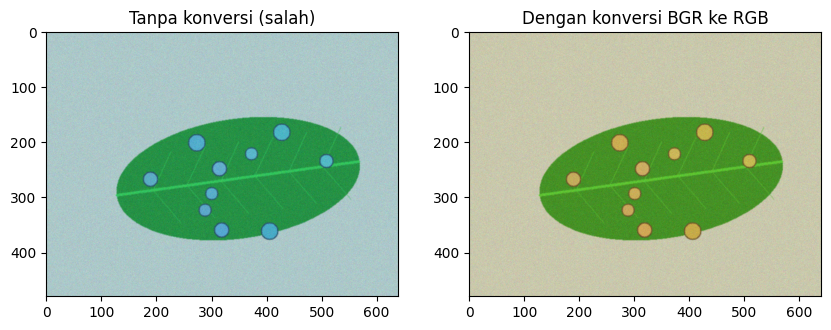

        count  mean   std   min   25%   50%   75%   max
kelas                                                  
berat    20.0  5.26  1.61  3.17  3.68  5.34  6.49  7.85
ringan   20.0  0.42  0.20  0.07  0.28  0.42  0.57  0.70
sehat    20.0  0.00  0.00  0.00  0.00  0.00  0.00  0.00


In [ ]:
import cv2, numpy as np, skimage, matplotlib.pyplot as plt, pandas as pd, time
from utils_cv import baca, tampil, kontras_bercak, statistik
print("OpenCV", cv2.__version__, "| NumPy", np.__version__, "| scikit-image", skimage.__version__)
img = baca("data/sintetis/citra/teh_041.png")
print("shape:", img.shape, "dtype:", img.dtype)
print("min-maks:", img.min(), img.max())
print("piksel (y=100, x=200) dalam urutan BGR:", img[100, 200])
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(img); plt.title("Tanpa konversi (salah)")
plt.subplot(1, 2, 2); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.title("Dengan konversi BGR ke RGB")
plt.savefig("hasil/b1_bgr_rgb.png"); plt.show()
lab = pd.read_csv("data/sintetis/label.csv")
print(lab.groupby("kelas").persen_bercak.describe().round(2))

**Langkah 1.5: Problem statement** (kerangka P1). *Ini draf; tulis ulang dengan kalimatmu sendiri sebelum dikumpulkan.*

> Bagi **petugas sortir kelompok tani teh rakyat di Kabupaten Sukabumi** yang menghadapi **penilaian mutu daun secara manual yang lama dan tidak seragam, terutama saat cahaya tidak merata dan bercak masih kecil**, kami membangun **SIMUTEH** yang menerima **foto daun teh di atas nampan sortir dari kamera telepon genggam** dan menghasilkan **kelas mutu (Sehat, Bercak Ringan, Bercak Berat) beserta persentase luas bercak**, sehingga **petugas memiliki pertimbangan yang konsisten dan cepat, sementara keputusan akhir tetap di tangan petugas**.

**Langkah 1.6: Diagram pipeline SIMUTEH enam tahap**, disimpan sebagai `hasil/b1_pipeline.png`.

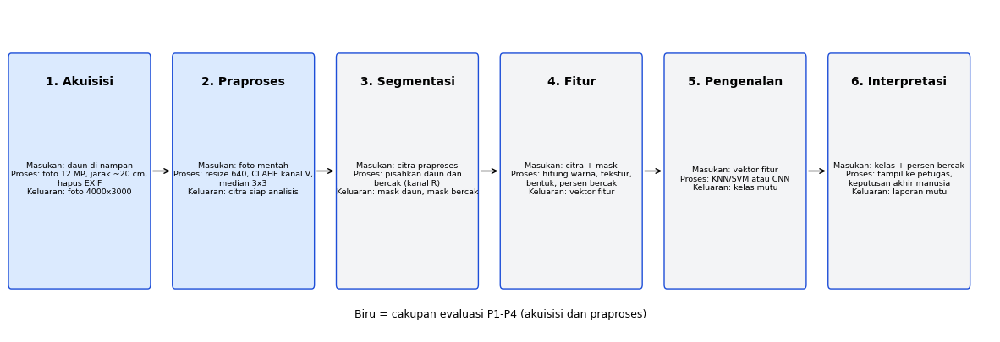

In [ ]:
from matplotlib.patches import FancyBboxPatch
tahap = [
 ("1. Akuisisi", "Masukan: daun di nampan\nProses: foto 12 MP, jarak ~20 cm,\nhapus EXIF\nKeluaran: foto 4000x3000"),
 ("2. Praproses", "Masukan: foto mentah\nProses: resize 640, CLAHE kanal V,\nmedian 3x3\nKeluaran: citra siap analisis"),
 ("3. Segmentasi", "Masukan: citra praproses\nProses: pisahkan daun dan\nbercak (kanal R)\nKeluaran: mask daun, mask bercak"),
 ("4. Fitur", "Masukan: citra + mask\nProses: hitung warna, tekstur,\nbentuk, persen bercak\nKeluaran: vektor fitur"),
 ("5. Pengenalan", "Masukan: vektor fitur\nProses: KNN/SVM atau CNN\nKeluaran: kelas mutu"),
 ("6. Interpretasi", "Masukan: kelas + persen bercak\nProses: tampil ke petugas,\nkeputusan akhir manusia\nKeluaran: laporan mutu"),
]
fig, ax = plt.subplots(figsize=(15, 5)); ax.axis("off"); ax.set_xlim(0, 18); ax.set_ylim(0, 4)
for i, (j, t) in enumerate(tahap):
    x = i * 3
    ax.add_patch(FancyBboxPatch((x + 0.05, 0.6), 2.5, 2.8, boxstyle="round,pad=0.05", fc="#dbeafe" if i < 2 else "#f3f4f6", ec="#1d4ed8"))
    ax.text(x + 1.3, 3.05, j, ha="center", fontweight="bold", fontsize=10)
    ax.text(x + 1.3, 1.9, t, ha="center", va="center", fontsize=6.8)
    if i < 5: ax.annotate("", xy=(x + 3.0, 2), xytext=(x + 2.6, 2), arrowprops=dict(arrowstyle="->"))
ax.text(9, 0.2, "Biru = cakupan evaluasi P1-P4 (akuisisi dan praproses)", ha="center", fontsize=9)
plt.savefig("hasil/b1_pipeline.png", dpi=150, bbox_inches="tight"); plt.show()

**Langkah 1.7: Tabel 6, risiko responsible computer vision SIMUTEH**

| Aspek | Risiko pada SIMUTEH | Mitigasi awal |
|---|---|---|
| Privasi citra | Foto tidak sengaja memuat wajah atau identitas petani; EXIF membocorkan lokasi kebun | Larangan wajah di bingkai; hapus EXIF sebelum disimpan; bila terlanjur, tutup wajah dengan kotak solid atau ambil ulang foto |
| Bias dan keadilan | Data sintetis hanya meniru satu jenis daun, warna latar, dan bercak bulat; kurang mewakili klon teh, cuaca, atau ponsel lain, sehingga akurasi bisa timpang antar kelompok tani | Uji pada foto nyata dari beberapa kebun dan ponsel; laporkan hasil per kondisi cahaya, bukan hanya rata-rata |
| Transparansi | Petugas tidak tahu seberapa yakin sistem dan apa yang diubah praproses | Tampilkan persentase bercak dan mask; simpan parameter praproses di JSON; nyatakan bahwa sistem alat bantu |
| Keamanan data | Foto dan label di repository publik atau perangkat hilang | Repository privat; akses terbatas kolaborator; jangan unggah data asli tanpa izin |
| Dampak sosial | Daun sehat dinilai berat merugikan harga petani; daun berat dinilai sehat merugikan pembeli dan menyebarkan penyakit; ketergantungan berlebihan pada sistem | Keputusan akhir tetap petugas; ambang konservatif; evaluasi kesalahan dua arah |
| Keterlacakan | Hasil tidak bisa diulang karena parameter, SEED, atau versi pustaka tidak tercatat | `requirements.txt`, SEED di README, `param_praproses.json`, tag `v0.1-praproses` |

**Langkah 1.8: commit** (jalankan di terminal atau sel Colab setelah repository dibuat):
```bash
git init && git add . && git commit -m "B1: setup lingkungan dan formulasi masalah"
```
Pembuatan repository GitHub `simuteh-2330511025` dan penambahan dosen sebagai kolaborator **harus kamu lakukan sendiri** di akun GitHub-mu.

### Jawaban Pertanyaan Analisis Bagian 1

**P1.1 Semantic gap.** Petugas sortir melihat sehelai daun teh hijau dengan bintik kuning pucat bertepi cokelat, lalu langsung menyimpulkan "ini terkena cacar daun". Komputer hanya menerima larik `480 x 640 x 3` bertipe `uint8` (Kode 1.1: shape `(480, 640, 3)`, dtype `uint8`). Contohnya piksel (y=100, x=200) bernilai BGR `[173 192 199]`: sekadar tiga angka 0 sampai 255, tanpa arti "daun", "nampan", atau "bercak". Jarak antara angka piksel dan makna "daun sakit" itulah semantic gap; seluruh tahap pipeline (praproses, segmentasi, fitur, pengenalan) bertugas menjembataninya.

**P1.2 Tiga sumber variasi paling mengganggu.**
1. *Pencahayaan*: kondisi gelap, terik, kontras rendah, dan bayangan (terbukti menurunkan KB pada Bagian 2). Ditangani tahap **praproses** (koreksi gamma, CLAHE).
2. *Skala/jarak pemotretan*: jarak yang berbeda mengubah ukuran bercak dalam piksel (P2.1). Ditangani tahap **akuisisi** (aturan jarak) dan sebagian oleh **fitur/geometri** (normalisasi ukuran).
3. *Derau dan latar*: derau sensor dan anyaman nampan. Ditangani tahap **praproses** (penapis median/Gaussian) dan **segmentasi** (memisahkan daun dari latar).

**P1.3 Tanpa konversi BGR ke RGB.** OpenCV menyimpan kanal berurutan B, G, R, sedangkan Matplotlib mengasumsikan R, G, B, sehingga kanal merah dan biru tertukar. Daun hijau relatif tetap hijau (kanal G tidak bertukar), tetapi bercak kuning (R dan G tinggi, B rendah) tampak kebiruan dan latar krem tampak kebiruan. Bila kesalahan terbawa ke fitur warna P9, rerata kanal R dan B, serta nilai Hue, ikut tertukar (kuning dengan Hue sekitar 25 menjadi biru). Model belajar dari fitur yang salah, atau data latih dan uji tidak konsisten, sehingga klasifikasi mutu menjadi tidak benar tanpa ada pesan galat.

**P1.4 Siapa yang diuntungkan dan dirugikan.**
- *Sehat dinilai bercak berat* (positif palsu): petani dirugikan karena daun baik dibuang atau dihargai rendah, dan kepercayaan pada alat turun.
- *Bercak berat dinilai sehat* (negatif palsu): pembeli atau pabrik menerima daun bermutu rendah, penyakit dapat menyebar bersama lot, dan reputasi kelompok tani rusak.
- Sistem yang tepat menguntungkan petugas (konsisten, cepat) dan kelompok tani (harga adil).
- Kaitan nilai: **adil** berarti kesalahan dua arah dievaluasi dan tidak membebani satu pihak (mis. petani kecil); **amanah** berarti sistem tidak mengklaim akurasi melebihi bukti, dan keputusan akhir tetap pada petugas yang bertanggung jawab.

## Bagian 2. Pembentukan Citra dan Ruang Warna

### Langkah 2.1 Lembar hitung manual (langkah, substitusi, satuan)

Rumus proyeksi pinhole: $x = f\,X / Z$. Data: f = 4,0 mm; piksel sensor 0,0014 mm; X = 5 mm; Z = 300 mm.

**a)** $x = 4{,}0 \times 5 / 300 = 0{,}0667$ mm. Jumlah piksel $= 0{,}0667 / 0{,}0014 = 47{,}6$ piksel.

**b)** Z = 600 mm: $x = 4{,}0 \times 5 / 600 = 0{,}0333$ mm, yaitu $0{,}0333/0{,}0014 = 23{,}8$ piksel. Jarak dua kali lebih jauh membuat bercak setengah lebih kecil: ukuran bayangan **berbanding terbalik** dengan jarak.

**c)** Syarat 10 piksel berarti $x = 10 \times 0{,}0014 = 0{,}014$ mm. Maka $Z = fX/x = 4{,}0 \times 5 / 0{,}014 = 1428{,}6$ mm (sekitar 1,43 m) pada foto resolusi penuh.

**d)** Faktor perkecilan $= 640/4000 = 0{,}16$. Diameter setelah diperkecil (Z = 300 mm): $47{,}6 \times 0{,}16 = 7{,}6$ piksel, **kurang dari 10**. Ukuran piksel efektif menjadi $0{,}0014/0{,}16 = 0{,}00875$ mm, sehingga jarak maksimum agar tetap 10 piksel: $Z = 4{,}0 \times 5 / (10 \times 0{,}00875) = 228{,}6$ mm (sekitar 23 cm).

**e)** Memori tanpa kompresi:
- Foto asli: $4000 \times 3000 \times 3 = 36{.}000{.}000$ byte $= 36$ MB (sekitar 34,3 MiB).
- Citra 640 x 480 berwarna: $640 \times 480 \times 3 = 921{.}600$ byte $= 900$ KiB.
- Citra 640 x 480 keabuan: $640 \times 480 = 307{.}200$ byte $= 300$ KiB.
- 300 foto asli: $300 \times 36$ MB $= 10{.}800$ MB $= 10{,}8$ GB.

**f)** $Y = 0{,}299R + 0{,}587G + 0{,}114B$.
- Bercak (196, 178, 86): $58{,}60 + 104{,}49 + 9{,}80 = 172{,}9 \approx 173$.
- Daun (52, 136, 60): $15{,}55 + 79{,}83 + 6{,}84 = 102{,}2 \approx 102$.
- Selisih $= 70{,}7 \approx 71$. Hasil `cv2.cvtColor` di bawah menghasilkan 173 dan 102 (cocok), dan Hue OpenCV bercak = 25, daun = 63 (rentang 0 sampai 179).

In [ ]:
# Pemeriksaan lembar hitung 2.1 dengan kode
f, px, X = 4.0, 0.0014, 5
for Z in (300, 600):
    x = f * X / Z; print(f"Z={Z} mm: x={x:.4f} mm = {x/px:.1f} piksel")
print("c) Z maks (10 px, resolusi penuh):", f*X/(10*px), "mm")
skala = 640/4000
print("d) diameter setelah resize:", f*X/300/px*skala, "px | Z maks:", f*X/(10*px/skala), "mm")
print("e) asli:", 4000*3000*3/1e6, "MB | 640x480 warna:", 640*480*3/1024, "KiB | abu:", 640*480/1024, "KiB | 300 foto:", 300*4000*3000*3/1e9, "GB")
pik = np.array([[[86, 178, 196], [60, 136, 52]]], np.uint8)   # urutan BGR
print("gray OpenCV:", cv2.cvtColor(pik, cv2.COLOR_BGR2GRAY).ravel(), "| HSV OpenCV (bercak, daun):", cv2.cvtColor(pik, cv2.COLOR_BGR2HSV)[0].tolist())

Z=300 mm: x=0.0667 mm = 47.6 piksel
Z=600 mm: x=0.0333 mm = 23.8 piksel
c) Z maks (10 px, resolusi penuh): 1428.5714285714284 mm
d) diameter setelah resize: 7.6190476190476195 px | Z maks: 228.57142857142858 mm
e) asli: 36.0 MB | 640x480 warna: 900.0 KiB | abu: 300.0 KiB | 300 foto: 10.8 GB
gray OpenCV: [173 102] | HSV OpenCV (bercak, daun): [[25, 143, 196], [63, 158, 136]]


### Langkah 2.2 Rencana akuisisi citra (Tabel)

| Butir | Rencana |
|---|---|
| Jarak pemotretan | 20 sampai 22 cm di atas daun (maksimum 22,9 cm dari hitungan 2.1 d) |
| Sudut | Tegak lurus (kamera menghadap ke bawah, sejajar nampan), hindari miring agar skala seragam |
| Resolusi minimum | Foto asli 12 MP (4000 x 3000), tanpa zoom digital; diperkecil ke lebar 640 setelah diambil |
| Alas dan acuan ukuran | Nampan anyaman berwarna polos seragam; tempel penggaris atau kotak acuan 5 cm di tepi nampan |
| Kondisi cahaya | Sampel mewakili lima kondisi: normal, gelap, terik, berkabut/kontras rendah, bayangan sebagian |
| Jumlah citra per kelas | Minimal 20 per kelas (sehat, ringan, berat) x 5 kondisi = 100 citra per kelas untuk penelitian lanjutan |
| Penamaan berkas | `teh_<nomor>_<kelas>_<kondisi>.jpg` tanpa nama petani atau lokasi |
| Izin | Persetujuan tertulis kelompok tani; tujuan dan pemakaian data dijelaskan |
| Metadata | Hapus EXIF (GPS, waktu, model ponsel) sebelum disimpan atau diunggah |
| Larangan | Tidak boleh ada wajah, tangan beridentitas, atau papan nama di dalam bingkai |

### Langkah 2.3 Kanal warna (Kode 2.1), teh_041 (berat, normal)

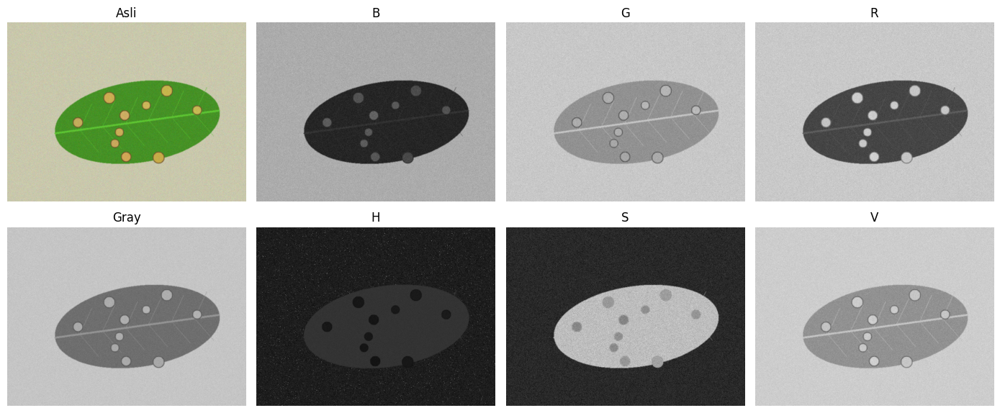

KB kanal B   : 3.88
KB kanal G   : 0.43
KB kanal R   : 10.93
KB kanal Gray: 4.45
KB kanal H   : 9.84
KB kanal S   : 2.54
KB kanal V   : 2.52


In [ ]:
nama = "teh_041.png"
img = baca(f"data/sintetis/citra/{nama}")
md_ = cv2.imread(f"data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"data/sintetis/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img); h, s, v = cv2.split(hsv)
kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}
tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()), baris=2, ukuran=(14, 6))
plt.savefig("hasil/b2_panel_kanal.png"); plt.show()
for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md_, mb):.2f}")

### Langkah 2.4 Eksperimen sampling dan kuantisasi (Kode 2.2) dengan tampilan visual

== Sampling ==
fx=0.5: ukuran (240, 320), KB=4.95
fx=0.2: ukuran (96, 128), KB=4.43
fx=0.1: ukuran (48, 64), KB=3.17
fx=0.05: ukuran (24, 32), KB=1.54


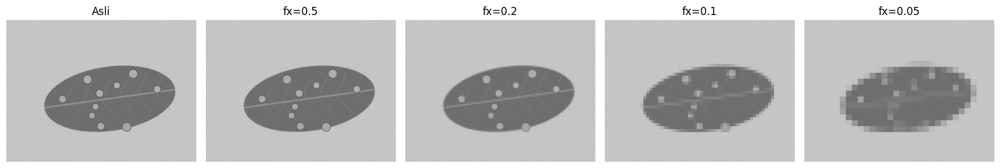

== Kuantisasi ==
k=1: 2 level, KB=3.23
k=2: 3 level, KB=3.23
k=3: 5 level, KB=5.47
k=4: 10 level, KB=3.65
k=8: 146 level, KB=4.45


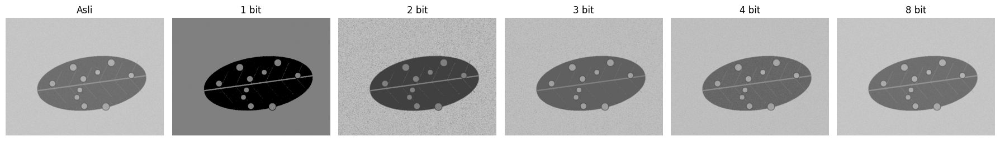

In [ ]:
daftar, judul = [gray], ["Asli"]
print("== Sampling ==")
for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1], interpolation=cv2.INTER_NEAREST)
    print(f"fx={fx}: ukuran {kecil.shape}, KB={kontras_bercak(besar, md_, mb):.2f}")
    daftar.append(besar); judul.append(f"fx={fx}")
tampil(daftar, judul, baris=1, ukuran=(16, 3)); plt.savefig("hasil/b2_sampling.png"); plt.show()
daftar, judul = [gray], ["Asli"]
print("== Kuantisasi ==")
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2 ** k); kuant = (gray // langkah) * langkah
    print(f"k={k}: {len(np.unique(kuant))} level, KB={kontras_bercak(kuant, md_, mb):.2f}")
    daftar.append(kuant); judul.append(f"{k} bit")
tampil(daftar, judul, baris=1, ukuran=(18, 3)); plt.savefig("hasil/b2_kuantisasi.png"); plt.show()

### Langkah 2.5 dan 2.6 Rerata KB per kanal dan kondisi (Kode 2.3), kelas berat dan kelas ringan


=== Tabel 8: rerata KB kelas berat ===
                   B     G      R  Gray     H     S     V
kondisi                                                  
normal          3.06  0.85  10.39  4.67  8.57  1.90  2.56
gelap           1.41  0.64  10.59  3.85  6.70  1.52  2.26
terang          2.46  1.04   7.74  4.42  5.83  1.21  2.39
kontras_rendah  1.06  0.34   4.17  2.22  2.29  0.42  1.32
bayangan        1.40  0.38   4.75  1.58  4.18  0.89  0.94

=== Tabel 8: rerata KB kelas ringan ===
                   B     G     R  Gray     H     S     V
kondisi                                                 
normal          1.27  1.05  9.44  3.21  8.88  1.20  1.59
gelap           0.86  0.46  7.39  2.63  5.02  0.91  1.77
terang          1.79  0.36  5.05  2.15  4.31  1.22  0.77
kontras_rendah  0.37  0.32  2.83  1.13  1.39  0.22  0.72
bayangan        0.67  0.25  4.32  1.12  4.03  0.65  0.54


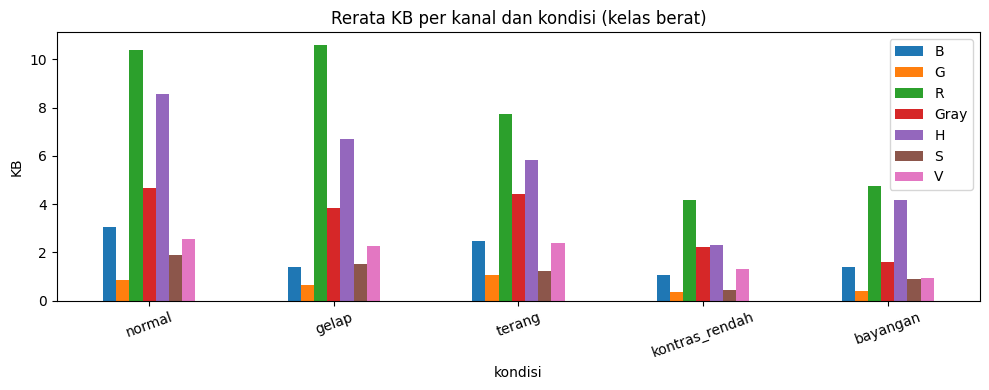

Kanal terbaik per kondisi (berat): {'normal': 'R', 'gelap': 'R', 'terang': 'R', 'kontras_rendah': 'R', 'bayangan': 'R'}
Kanal terbaik per kondisi (ringan): {'normal': 'R', 'gelap': 'R', 'terang': 'R', 'kontras_rendah': 'R', 'bayangan': 'R'}


In [ ]:
def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img); h, s, v = cv2.split(hsv)
    return {"B": b, "G": g, "R": r, "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), "H": h, "S": s, "V": v}
URUT = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
label = pd.read_csv("data/sintetis/label.csv")
tabel = {}
for kls in ["berat", "ringan"]:
    baris = []
    for _, d in label[label.kelas == kls].iterrows():
        im = baca(f"data/sintetis/citra/{d.nama_file}")
        m_d = cv2.imread(f"data/sintetis/mask_daun/{d.nama_file}", 0)
        m_b = cv2.imread(f"data/sintetis/mask_bercak/{d.nama_file}", 0)
        kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
        kb["kondisi"] = d.kondisi_cahaya; baris.append(kb)
    tabel[kls] = pd.DataFrame(baris).groupby("kondisi").mean().round(2).loc[URUT]
    tabel[kls].to_csv(f"hasil/b2_kb_kanal_{kls}.csv")
    print(f"\n=== Tabel 8: rerata KB kelas {kls} ==="); print(tabel[kls])
tabel["berat"].plot(kind="bar", figsize=(10, 4), title="Rerata KB per kanal dan kondisi (kelas berat)")
plt.ylabel("KB"); plt.xticks(rotation=20); plt.tight_layout(); plt.savefig("hasil/b2_grafik_kb.png"); plt.show()
print("Kanal terbaik per kondisi (berat):", tabel["berat"].idxmax(axis=1).to_dict())
print("Kanal terbaik per kondisi (ringan):", tabel["ringan"].idxmax(axis=1).to_dict())

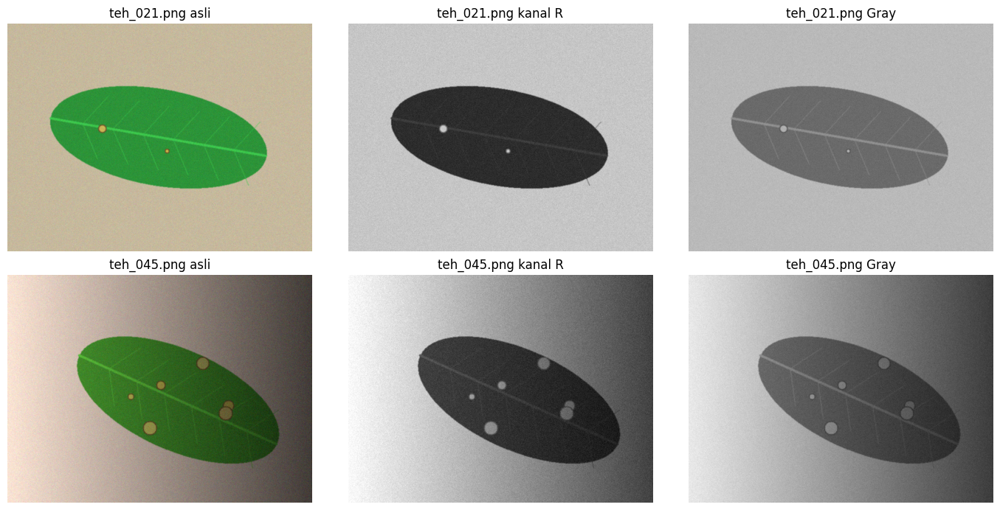

In [ ]:
# Panel kanal terbaik: teh_021 (ringan, normal) dan teh_045 (berat, bayangan)
fig_list, fig_jd = [], []
for nm in ["teh_021.png", "teh_045.png"]:
    im = baca(f"data/sintetis/citra/{nm}")
    fig_list += [im, im[:, :, 2], cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)]
    fig_jd += [f"{nm} asli", f"{nm} kanal R", f"{nm} Gray"]
tampil(fig_list, fig_jd, baris=2, ukuran=(14, 7)); plt.savefig("hasil/b2_panel_terbaik.png"); plt.show()

### Jawaban Pertanyaan Analisis Bagian 2

**P2.1 Aturan pemotretan.** Dari 2.1 d), setelah diperkecil ke lebar 640, bercak 5 mm hanya 7,6 piksel pada jarak 30 cm (di bawah syarat 10 piksel); jarak maksimum agar tetap 10 piksel adalah 22,9 cm. Bidang pandang pada jarak itu sekitar 32 cm (lebar sensor 5,6 mm / f 4 mm x 228 mm), cukup untuk satu daun di atas nampan. **Aturan untuk petugas:** *"Pegang ponsel tegak lurus sekitar satu jengkal (20 cm) di atas daun, jangan lebih jauh dari 22 cm, pakai kamera resolusi penuh 12 MP, tanpa zoom."* Bila ingin memotret lebih jauh, resolusi kerja harus dinaikkan (mis. lebar 1280 piksel memberi jarak maksimum sekitar 45 cm).

**P2.2 Kanal terbaik.** Kanal **R** memberi KB tertinggi di kelima kondisi (kelas berat: normal 10,39; gelap 10,59; terang 7,74; kontras rendah 4,17; bayangan 4,75), dan juga pada kelas ringan. Penjelasan fisik: klorofil daun menyerap merah dan biru dan memantulkan terutama hijau, sehingga R daun rendah (sekitar 52). Bercak pucat kekuningan memantulkan merah dan hijau sekaligus, sehingga R bercak tinggi (sekitar 196): selisih sekitar 144 tingkat. Pada kanal G daun dan bercak sama-sama cukup terang (136 dan 178), selisihnya kecil sehingga KB G hanya 0,34 sampai 1,04. Kanal B berselisih sedikit (60 vs 86).

**P2.3 Apakah H tahan cahaya?** Hasil mendukung **sebagian**. KB kanal H lebih tinggi dari V di semua kondisi, tetapi tidak kebal: H turun dari 8,57 (normal) menjadi 6,70 (gelap, turun 22%), 5,83 (terang, turun 32%), dan 4,18 (bayangan, turun 51%). V turun dari 2,56 menjadi 2,26 (gelap), 2,39 (terang), dan 0,94 (bayangan, turun 63%). Jadi H jauh lebih informatif daripada V karena V memang mengukur kecerahan, tetapi Hue tidak sepenuhnya invarian: pada piksel gelap atau jenuh, derau membuat rasio kanal tidak stabil, dan Hue mudah bergeser.

**P2.4 Kuantisasi dan keterbatasan KB.** Tidak. Pada teh_041, KB 3 bit (5 level) = 5,47, lebih tinggi daripada 8 bit (146 level) = 4,45, padahal citra 3 bit tampak berpita (*banding*), tulang daun dan gradasi hilang. KB hanya membandingkan rerata bercak dan daun terhadap simpangan baku daun; kuantisasi kasar meratakan variasi daun (penyebut mengecil) sehingga KB naik, walau informasi visual hilang. KB tidak mengukur kemiripan bentuk, tepi, atau tekstur, jadi harus dipasangkan dengan pemeriksaan visual dan ukuran lain.

**P2.5 Sampling.** KB turun dari 4,95 (fx=0,5) ke 4,43 (0,2), 3,17 (0,1), dan 1,54 (0,05). Pada panel `b2_sampling.png` (teh_041), sampai fx=0,2 semua bercak masih tampak jelas. Pada **fx=0,1** (lebar 64 piksel) bercak mulai sulit dibedakan: berubah menjadi blok kasar 1 sampai 3 piksel dengan tepi kabur dan bercak terkecil nyaris menyatu dengan daun; pada fx=0,05 sebagian besar bercak hilang. Secara hitungan, bercak berat berdiameter sekitar 14 sampai 32 piksel (radius 5 sampai 14 ditambah tepi 2) dan bercak ringan 10 sampai 18 piksel pada citra 640 piksel; pada fx=0,1 menjadi 1 sampai 3 piksel dan 1 sampai 2 piksel. Ini konsisten dengan hitungan 2.1 d): bercak yang kurang dari sekitar 10 piksel sudah berada di ambang terlihat. *(Cocokkan dengan gambar milikmu sendiri.)*

**P2.6 Risiko EXIF.** EXIF dapat membocorkan koordinat GPS (lokasi kebun), tanggal dan jam pemotretan (pola kerja), model dan nomor seri ponsel, kadang nama pemilik dan gambar mini. Yang dirugikan: petani (lokasi kebun dan kebiasaannya diketahui orang luar, risiko pencurian atau penekanan harga) dan kelompok tani. Rencana akuisisi mencegahnya dengan menghapus EXIF sebelum disimpan, repository privat, penamaan berkas tanpa nama atau lokasi, dan izin tertulis.

## Bagian 3. Histogram dan Perbaikan Citra

### Langkah 3.1 Lembar hitung manual

Matriks M (3 bit, L = 8):
```
[[1,2,2,3],[2,2,3,3],[1,2,3,4],[2,3,3,2]]
```
**a) Histogram.** Jumlah piksel: r=1 → 2, r=2 → 7, r=3 → 6, r=4 → 1, lainnya 0 (total 16). Diagram batang: tinggi 2, 7, 6, 1 untuk r = 1, 2, 3, 4 (gambar dibuat pada sel kode di bawah).

**b) Peregangan kontras** ke 0..7 dengan rmin = 1 dan rmax = 4: $s = \mathrm{round}\big((r-1)/(4-1)\times 7\big)$. Hasil: 1→0, 2→2,33→**2**, 3→4,67→**5**, 4→7.
```
[[0,2,2,5],[2,2,5,5],[0,2,5,7],[2,5,5,2]]
```
**c) Ekualisasi** ($s = \mathrm{round}(7 \times \mathrm{CDF})$):

| r | n | PDF = n/16 | CDF | 7 x CDF | s |
|---|---|---|---|---|---|
| 0 | 0 | 0 | 0 | 0 | 0 |
| 1 | 2 | 0,1250 | 0,1250 | 0,875 | 1 |
| 2 | 7 | 0,4375 | 0,5625 | 3,9375 | 4 |
| 3 | 6 | 0,3750 | 0,9375 | 6,5625 | 7 |
| 4 | 1 | 0,0625 | 1,0000 | 7,0 | 7 |
| 5 | 0 | 0 | 1,0 | 7,0 | 7 |
| 6 | 0 | 0 | 1,0 | 7,0 | 7 |
| 7 | 0 | 0 | 1,0 | 7,0 | 7 |

Pemetaan: 1→1, 2→4, 3→7, 4→7. Matriks hasil:
```
[[1,4,4,7],[4,4,7,7],[1,4,7,7],[4,7,7,4]]
```
**d) Operasi titik 8 bit.**
- Negatif r = 60: $255 - 60 = 195$.
- Kontras $s = 1{,}4r - 30$: untuk r = 120, $s = 168 - 30 = 138$; untuk r = 210, $s = 294 - 30 = 264$, di-*clip* menjadi **255**.
- Gamma r = 100: $s = 255\,(100/255)^{\gamma}$. Untuk γ = 0,6: $(0{,}3922)^{0{,}6} = 0{,}5703$, jadi $s \approx 145$ (mencerahkan). Untuk γ = 1,8: $(0{,}3922)^{1{,}8} = 0{,}1855$, jadi $s \approx 47$ (menggelapkan).

histogram: [0 2 7 6 1 0 0 0]
regang:
 [[0 2 2 5]
 [2 2 5 5]
 [0 2 5 7]
 [2 5 5 2]]
s per r: [0 1 4 7 7 7 7 7]
ekualisasi:
 [[1 4 4 7]
 [4 4 7 7]
 [1 4 7 7]
 [4 7 7 4]]
negatif 60: 195 | kontras 120: 138.0 | kontras 210: 255
gamma0.6: 145.4 | gamma1.8: 47.3


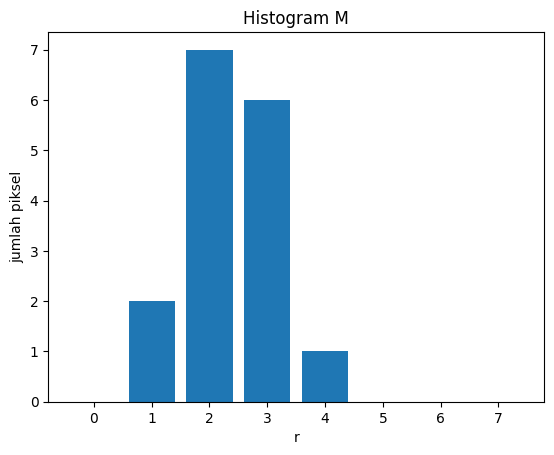

In [ ]:
M = np.array([[1,2,2,3],[2,2,3,3],[1,2,3,4],[2,3,3,2]])
cnt = np.bincount(M.ravel(), minlength=8); cdf = np.cumsum(cnt)/16; s = np.round(7*cdf).astype(int)
print("histogram:", cnt); print("regang:\n", np.round((M-M.min())/(M.max()-M.min())*7).astype(int))
print("s per r:", s); print("ekualisasi:\n", s[M])
print("negatif 60:", 255-60, "| kontras 120:", 1.4*120-30, "| kontras 210:", min(255, 1.4*210-30))
print("gamma0.6:", round(255*(100/255)**0.6, 1), "| gamma1.8:", round(255*(100/255)**1.8, 1))
plt.bar(range(8), cnt); plt.xlabel("r"); plt.ylabel("jumlah piksel"); plt.title("Histogram M"); plt.savefig("hasil/b3_hist_manual.png"); plt.show()

### Langkah 3.2 Diagnosis mutu (Kode 3.1) dan Tabel 9

teh_041.png {'rerata': 176.8, 'simpangan_baku': 36.5, 'min': 77, 'maks': 223, 'persen_gelap': 0.0, 'persen_terang': 4.0}
teh_042.png {'rerata': 117.0, 'simpangan_baku': 36.7, 'min': 8, 'maks': 177, 'persen_gelap': 9.2, 'persen_terang': 0.0}
teh_043.png {'rerata': 210.7, 'simpangan_baku': 27.8, 'min': 137, 'maks': 250, 'persen_gelap': 0.0, 'persen_terang': 75.7}
teh_044.png {'rerata': 154.8, 'simpangan_baku': 15.0, 'min': 98, 'maks': 195, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_045.png {'rerata': 132.2, 'simpangan_baku': 58.4, 'min': 24, 'maks': 250, 'persen_gelap': 1.7, 'persen_terang': 16.4}


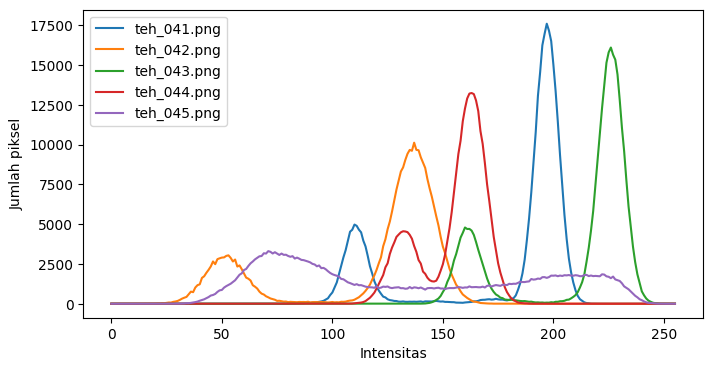


-- teh_021 sampai teh_025 (ringan) --
teh_021 {'rerata': 167.1, 'simpangan_baku': 33.5, 'min': 78, 'maks': 207, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_022 {'rerata': 126.6, 'simpangan_baku': 41.7, 'min': 14, 'maks': 187, 'persen_gelap': 12.4, 'persen_terang': 0.0}
teh_023 {'rerata': 215.5, 'simpangan_baku': 28.5, 'min': 128, 'maks': 255, 'persen_gelap': 0.0, 'persen_terang': 76.6}
teh_024 {'rerata': 154.2, 'simpangan_baku': 16.6, 'min': 99, 'maks': 197, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_025 {'rerata': 126.7, 'simpangan_baku': 56.7, 'min': 26, 'maks': 249, 'persen_gelap': 1.6, 'persen_terang': 13.5}
rerata kelima citra ringan: {'rerata': 158.0, 'simpangan_baku': 35.4, 'min': 69.0, 'maks': 219.0, 'persen_gelap': 2.8, 'persen_terang': 18.0}


In [ ]:
nama_list = ["teh_041.png", "teh_042.png", "teh_043.png", "teh_044.png", "teh_045.png"]
plt.figure(figsize=(8, 4))
for nm in nama_list:
    g_ = cv2.cvtColor(baca(f"data/sintetis/citra/{nm}"), cv2.COLOR_BGR2GRAY)
    print(nm, statistik(g_))
    plt.plot(cv2.calcHist([g_], [0], None, [256], [0, 256]), label=nm)
plt.xlabel("Intensitas"); plt.ylabel("Jumlah piksel"); plt.legend(); plt.savefig("hasil/b3_histogram_5kondisi.png"); plt.show()
print("\n-- teh_021 sampai teh_025 (ringan) --")
st = [statistik(cv2.cvtColor(baca(f"data/sintetis/citra/teh_{i:03d}.png"), cv2.COLOR_BGR2GRAY)) for i in range(21, 26)]
for i, x in zip(range(21, 26), st): print(f"teh_{i:03d}", x)
print("rerata kelima citra ringan:", pd.DataFrame(st).mean().round(1).to_dict())

**Tabel 9. Diagnosis mutu citra** (angka dari keluaran sel di atas)

| Citra | Rerata | Simp. baku | Min-maks | % gelap | % terang | Diagnosis | Usulan perbaikan |
|---|---|---|---|---|---|---|---|
| teh_041 (normal) | 176,8 | 36,5 | 77-223 | 0,0 | 4,0 | Pencahayaan dan kontras baik | Cukup penapis derau |
| teh_042 (gelap) | 117,0 | 36,7 | 8-177 | 9,2 | 0,0 | Histogram bergeser ke kiri, kontras sedang | Peregangan kontras (persentil 2 dan 98); pencerahan gamma < 1 diuji dan ternyata tidak menaikkan KB (Langkah 3.5) |
| teh_043 (terang) | 210,7 | 27,8 | 137-250 | 0,0 | 75,7 | Histogram menumpuk di kanan, banyak piksel hampir jenuh | Koreksi gamma > 1 (menggelapkan) |
| teh_044 (kontras rendah) | 154,8 | 15,0 | 98-195 | 0,0 | 0,0 | Histogram sempit di tengah | Peregangan kontras (persentil 2 dan 98) |
| teh_045 (bayangan) | 132,2 | 58,4 | 24-250 | 1,7 | 16,4 | Histogram dua puncak (sisi teduh dan sisi terang), simpangan baku terbesar | CLAHE (perbaikan lokal), bukan ekualisasi global |
| teh_021 sampai 025 (ringan, rata-rata) | 158,0 | 35,4 | 69-219 | 2,8 | 18,0 | Campuran kelima kondisi; statistik rata-rata tidak mewakili satu kondisi | Pilih perbaikan per kondisi (lihat P3.5) |

### Langkah 3.3 Perbaikan citra kondisi bayangan (Kode 3.2) dan Tabel 10

persentil 2 dan 98: 51.0 232.0
    Metode           Parameter   KB  Simpangan baku
      asli                   - 1.11            58.4
   negatif             255 - r 1.11            58.4
  cerah+50                 +50 1.11            54.7
   kontras alpha 1,5; beta -40 1.11            78.8
    regang      persentil 2-98 1.14            81.9
  gamma0.5           gamma 0,5 1.00            41.0
  gamma1.8           gamma 1,8 1.29            65.3
ekualisasi              global 0.90            73.5
     CLAHE      clip 2; tile 8 1.71            48.7


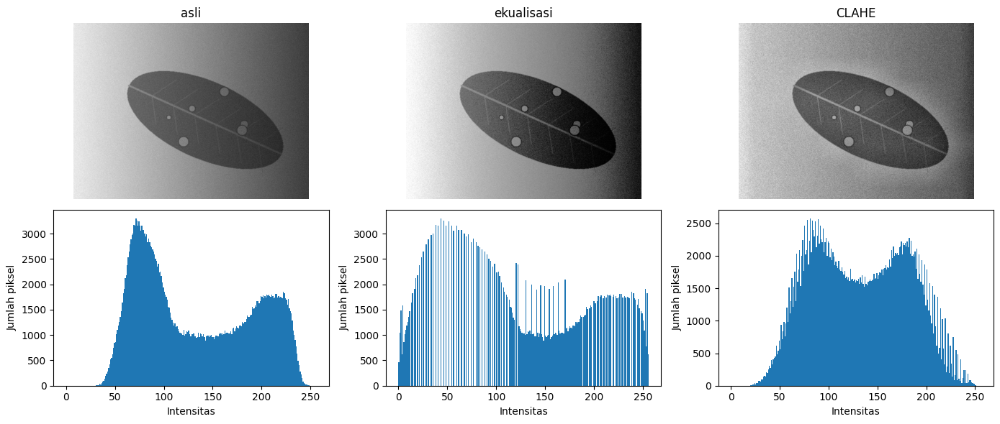

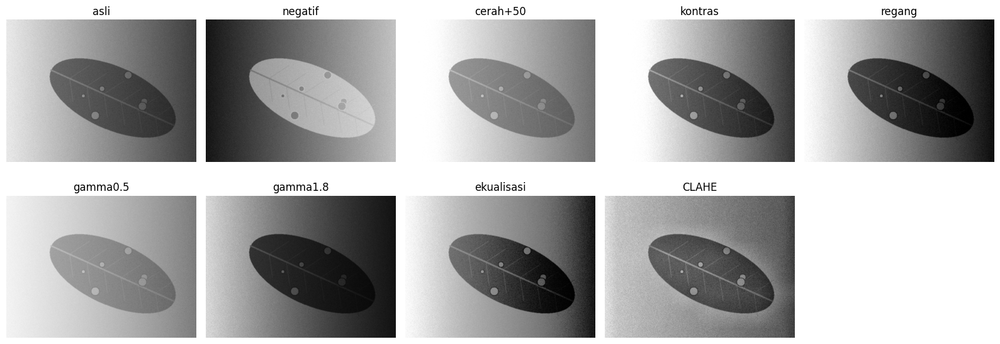

In [ ]:
nama = "teh_045.png"
img = baca(f"data/sintetis/citra/{nama}")
md_ = cv2.imread(f"data/sintetis/mask_daun/{nama}", 0); mb = cv2.imread(f"data/sintetis/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
def gamma_lut(g):
    return np.array([255 * (i / 255) ** g for i in range(256)]).clip(0, 255).astype(np.uint8)
rmin, rmax = np.percentile(gray, (2, 98)); print("persentil 2 dan 98:", rmin, rmax)
hasil = {
 "asli": gray, "negatif": 255 - gray, "cerah+50": cv2.add(gray, 50),
 "kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
 "regang": np.clip((gray.astype(float) - rmin) / (rmax - rmin) * 255, 0, 255).astype(np.uint8),
 "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)), "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)),
 "ekualisasi": cv2.equalizeHist(gray), "CLAHE": cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)}
parameter = {"asli": "-", "negatif": "255 - r", "cerah+50": "+50", "kontras": "alpha 1,5; beta -40",
             "regang": "persentil 2-98", "gamma0.5": "gamma 0,5", "gamma1.8": "gamma 1,8", "ekualisasi": "global", "CLAHE": "clip 2; tile 8"}
rows = []
for nm, c in hasil.items():
    rows.append([nm, parameter[nm], round(kontras_bercak(c, md_, mb), 2), round(float(c.std()), 1)])
tabel10 = pd.DataFrame(rows, columns=["Metode", "Parameter", "KB", "Simpangan baku"])
print(tabel10.to_string(index=False)); tabel10.to_csv("hasil/b3_tabel10.csv", index=False)
# Gambar 4: citra dan histogram sebelum/sesudah
pilih = ["asli", "ekualisasi", "CLAHE"]
fig, ax = plt.subplots(2, 3, figsize=(14, 6))
for j, nm in enumerate(pilih):
    ax[0, j].imshow(hasil[nm], cmap="gray", vmin=0, vmax=255); ax[0, j].set_title(nm); ax[0, j].axis("off")
    ax[1, j].hist(hasil[nm].ravel(), bins=256, range=(0, 256)); ax[1, j].set_xlabel("Intensitas"); ax[1, j].set_ylabel("Jumlah piksel")
plt.tight_layout(); plt.savefig("hasil/b3_gambar4.png"); plt.show()
# semua metode berdampingan
tampil(list(hasil.values()), list(hasil.keys()), baris=2, ukuran=(16, 6)); plt.savefig("hasil/b3_semua_metode.png"); plt.show()

**Kolom "Pengamatan visual" Tabel 10:** isi sendiri dengan melihat gambar `b3_semua_metode.png` dan `b3_gambar4.png` (mis. apakah sisi teduh menjadi terlihat, apakah derau membesar, apakah bercak lebih jelas). Pengamatan visual harus berasal dari penglihatanmu sendiri, bukan dari saya.

### Langkah 3.4 Parameter CLAHE dan citra warna (Kode 3.3)

clip tile  KB
 1.0   4  1.91
 1.0   8  1.68
 1.0  16  1.69
 2.0   4  1.94
 2.0   8  1.71
 2.0  16  1.68
 4.0   4  1.89
 4.0   8  1.58
 4.0  16  1.52


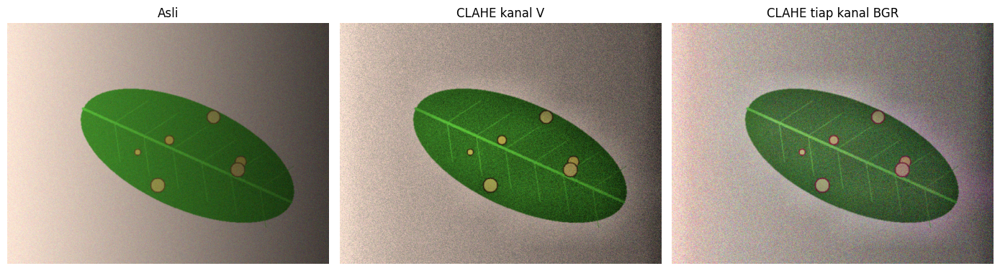

via V    rerata geser Hue di daun = 0.03 | KB R = 5.56 | KB H = 5.10
via BGR  rerata geser Hue di daun = 12.26 | KB R = 3.45 | KB H = 0.31
asli: KB R = 4.32 | KB H = 5.09


In [ ]:
print("clip tile  KB")
for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:
        c = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(gray)
        print(f"{clip:4.1f} {tile:3d}  {kontras_bercak(c, md_, mb):.2f}")
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hsv[:, :, 2] = clahe.apply(hsv[:, :, 2]); via_v = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
via_bgr = cv2.merge([clahe.apply(c) for c in cv2.split(img)])
tampil([img, via_v, via_bgr], ["Asli", "CLAHE kanal V", "CLAHE tiap kanal BGR"]); plt.savefig("hasil/b3_clahe_warna.png"); plt.show()
# bukti kuantitatif: pergeseran Hue di area daun dan KB kanal R/H
H0 = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)[:, :, 0].astype(float)
for nm, o in [("via V", via_v), ("via BGR", via_bgr)]:
    ho = cv2.cvtColor(o, cv2.COLOR_BGR2HSV)[:, :, 0].astype(float); dlt = np.abs(ho - H0); dlt = np.minimum(dlt, 180 - dlt)
    print(f"{nm:8s} rerata geser Hue di daun = {dlt[md_>0].mean():.2f} | KB R = {kontras_bercak(o[:,:,2], md_, mb):.2f} | KB H = {kontras_bercak(cv2.cvtColor(o, cv2.COLOR_BGR2HSV)[:,:,0], md_, mb):.2f}")
print("asli: KB R =", round(kontras_bercak(img[:, :, 2], md_, mb), 2), "| KB H =", round(kontras_bercak(H0.astype(np.uint8), md_, mb), 2))

### Langkah 3.5 Satu perbaikan per kondisi, diterapkan pada kelas berat dan ringan

       kondisi   citra  kelas             perbaikan  KB_sebelum  KB_sesudah
         gelap teh_042  berat regang persentil 2-98        3.41        3.71
         gelap teh_022 ringan regang persentil 2-98        2.26        2.53
        terang teh_043  berat             gamma 1,8        4.78        5.22
        terang teh_023 ringan             gamma 1,8        1.67        1.83
kontras_rendah teh_044  berat regang persentil 2-98        1.89        2.02
kontras_rendah teh_024 ringan regang persentil 2-98        1.64        1.75
      bayangan teh_045  berat  CLAHE clip 2, tile 8        1.11        1.71
      bayangan teh_025 ringan  CLAHE clip 2, tile 8        1.69        1.76


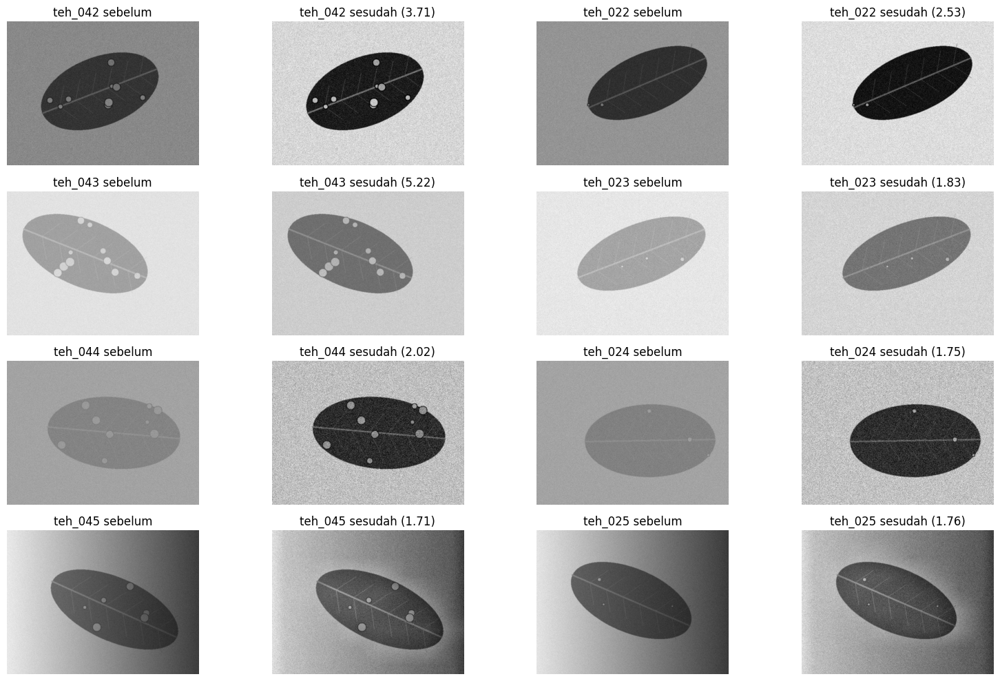

In [ ]:
def regang(g):
    a, b_ = np.percentile(g, (2, 98)); return np.clip((g.astype(float) - a) / (b_ - a) * 255, 0, 255).astype(np.uint8)
perbaikan = {
 "gelap":          ("regang persentil 2-98", regang),
 "terang":         ("gamma 1,8",            lambda g: cv2.LUT(g, gamma_lut(1.8))),
 "kontras_rendah": ("regang persentil 2-98", regang),
 "bayangan":       ("CLAHE clip 2, tile 8", lambda g: cv2.createCLAHE(2.0, (8, 8)).apply(g)),
}
pasangan = {"gelap": ("teh_042", "teh_022"), "terang": ("teh_043", "teh_023"), "kontras_rendah": ("teh_044", "teh_024"), "bayangan": ("teh_045", "teh_025")}
rows, daftar, judul = [], [], []
for kond, (nm_b, nm_r) in pasangan.items():
    nm_perb, fn = perbaikan[kond]
    for kelas, nm in [("berat", nm_b), ("ringan", nm_r)]:
        g_ = cv2.cvtColor(baca(f"data/sintetis/citra/{nm}.png"), cv2.COLOR_BGR2GRAY); o = fn(g_)
        a = cv2.imread(f"data/sintetis/mask_daun/{nm}.png", 0); b_ = cv2.imread(f"data/sintetis/mask_bercak/{nm}.png", 0)
        k0, k1 = kontras_bercak(g_, a, b_), kontras_bercak(o, a, b_)
        rows.append([kond, nm, kelas, nm_perb, round(k0, 2), round(k1, 2)])
        daftar += [g_, o]; judul += [f"{nm} sebelum", f"{nm} sesudah ({k1:.2f})"]
tabel35 = pd.DataFrame(rows, columns=["kondisi", "citra", "kelas", "perbaikan", "KB_sebelum", "KB_sesudah"])
print(tabel35.to_string(index=False)); tabel35.to_csv("hasil/b3_tabel_langkah35.csv", index=False)
tampil(daftar, judul, baris=4, ukuran=(16, 10)); plt.savefig("hasil/b3_sebelum_sesudah.png"); plt.show()

### Jawaban Pertanyaan Analisis Bagian 3

**P3.1 Nilai 3 dan 4 sama setelah ekualisasi.** Pada hitung manual, 3 dan 4 sama-sama dipetakan ke 7. Dua tingkat intensitas yang tadinya berbeda kini identik, sehingga perbedaan itu **tidak dapat dipulihkan** lagi (informasi hilang; 4 level asli menjadi 3 level hasil: 1, 4, 7). Ekualisasi hanya memetakan ulang nilai yang sudah ada dengan fungsi tak menurun; ia merenggangkan jarak antar-level yang padat, tetapi tidak menambah detail baru dan dapat menggabungkan level yang jarang. Karena itu tampilan menjadi lebih kontras, bukan lebih kaya informasi.

**P3.2 Ekualisasi global vs CLAHE pada citra bayangan.** Pada teh_045 histogram berbentuk dua puncak (sisi teduh gelap dan sisi terang) dengan simpangan baku 58,4. Ekualisasi global memakai satu fungsi CDF untuk seluruh citra, sehingga ia meregangkan jarak antara dua puncak itu (perbedaan teduh-terang) dan memampatkan rentang di dalam tiap sisi, tempat daun dan bercak berada. Hasilnya KB turun dari 1,11 menjadi 0,90. CLAHE memperbaiki per blok 8 x 8 sehingga tiap area dinormalkan menurut kondisi lokalnya, dan clip limit menahan penguatan derau; KB naik menjadi 1,71. Ini sama dengan kasus kebun teh pada slide P3: sebagian daun teduh dan sebagian terik, sehingga perbaikan harus lokal.

**P3.3 Persentil vs min-maks.** Peregangan min-maks gagal jika ada satu atau beberapa piksel ekstrem (derau, pantulan). Contoh: bila hampir semua piksel bernilai 50 sampai 60 tetapi ada satu piksel derau 0 dan satu piksel 255, maka rmin = 0 dan rmax = 255, sehingga $s = (60-0)/(255-0)\times 255 = 60$: tidak ada peregangan sama sekali. Persentil 2 dan 98 mengabaikan 2% piksel ekstrem di tiap ujung, sehingga rentang efektif (pada teh_045: 51 sampai 232) mencerminkan mayoritas piksel.

**P3.4 CLAHE di kanal V, bukan di tiap kanal BGR.** CLAHE per kanal mengubah rasio antar-kanal secara berbeda di tiap blok, sehingga warna bergeser (warna palsu). Buktinya pada Kode 3.3 (teh_045): rerata pergeseran Hue di area daun hanya **0,03** jika via V, tetapi **12,26** jika via BGR (skala Hue 0 sampai 179). KB kanal H via V = 5,10, sedangkan via BGR anjlok menjadi 0,31; KB kanal R via V = 5,56 vs via BGR = 3,45. CLAHE pada V hanya mengubah kecerahan dan mempertahankan Hue dan Saturasi.

**P3.5 Satu pengaturan atau adaptif?** Satu pengaturan tidak cukup. Pada Bagian 5 (kanal R, 40 citra berbercak), CLAHE clip 2 dengan median 3 menaikkan KB untuk gelap (8,99 menjadi 16,79) dan bayangan (4,53 menjadi 7,76) tetapi **menurunkan** KB kondisi terang (6,39 menjadi 6,14), sedangkan tanpa CLAHE KB terang naik menjadi 10,61. Aturan sederhana berbasis statistik histogram citra keabuan: *jika simpangan baku > 50 (bayangan) maka CLAHE clip 2, tile 4; jika rerata < 140 dan simpangan baku < 40 (gelap) maka CLAHE clip 1; selain itu tanpa CLAHE.* Aturan ini menghasilkan rerata KB 11,38, lebih tinggi daripada pengaturan tetap clip 1 (10,47) dan tanpa CLAHE (10,85). Perhatikan juga hasil Langkah 3.5: mencerahkan citra gelap dengan gamma < 1 justru menurunkan KB (teh_042: 3,41 menjadi 2,83), sebab KB mengukur keterpisahan relatif terhadap variasi daun, bukan kecerahan yang enak dilihat; jadi "tampak lebih indah" tidak sama dengan "bercak lebih mudah dipisahkan". Catatan: ambang tersebut dipilih dari data sintetis yang sama, jadi harus diuji ulang pada foto nyata.

**P3.6 Perbaikan berlebihan.** Contoh: CLAHE dengan clip limit besar (mis. 4) dan tile kecil pada daun sehat memperkuat derau dan tulang daun menjadi bintik atau garis terang yang mirip bercak; gamma yang terlalu kecil (0,5) membuat daun sehat tampak pucat sehingga mengaburkan batas dengan bercak. Pencegahan: batasi clip limit (≤ 2), pilih parameter berdasarkan bukti (KB dan simpangan baku daun sehat), jalankan **uji bercak palsu pada kelas sehat** (Langkah 5.3), dan simpan parameter di JSON agar dapat diaudit.

## Bagian 4. Konvolusi dan Penapisan Spasial

### Langkah 4.1 Lembar hitung manual

```
P = [[52, 55, 61, 58],     Q = [[70, 72, 75],      kernel tajam = [[ 0,-1, 0],
     [59,255, 64, 60],          [74,120, 78],                      [-1, 5,-1],
     [62, 60,  0, 57],          [73, 76, 79]]                      [ 0,-1, 0]]
     [58, 61, 59, 63]]
```
**a)** Keluaran 2 x 2 (posisi valid) memakai jendela 3 x 3 pada empat posisi. Setiap jendela memuat **kedua** piksel ekstrem (255 di (1,1) dan 0 di (2,2)).

- *Rerata 3 x 3:* jumlah jendela (0,0) = 52+55+61+59+255+64+62+60+0 = 668, jadi 668/9 = **74,22**. Hasil keempat posisi: 74,22; 74,44; 75,33; 75,44.
- *Gaussian 1/16:* posisi (0,0): (1·52+2·55+1·61) + (2·59+4·255+2·64) + (1·62+2·60+1·0) = 223 + 1266 + 182 = 1671, jadi 1671/16 = **104,44**. Hasil keempat posisi: 104,44; 77,38; 77,25; 57,44.
- *Median 3 x 3:* jendela (0,0) terurut: 0, 52, 55, 59, **60**, 61, 62, 64, 255, median = 60. Keempat posisi menghasilkan **60, 60, 60, 60**.

**b)** Piksel tengah Q (120) dengan kernel tajam: $5(120) - 72 - 74 - 78 - 76 = 600 - 300 = 300$, di-*clip* menjadi **255**.

**c)** Baris [12, 30, 45, 70], padding satu piksel:
- Zero padding: [0, 12, 30, 45, 70, 0]; rerata 1 x 3 piksel pertama = (0+12+30)/3 = **14,0**.
- Replicate: [12, 12, 30, 45, 70, 70]; rerata = (12+12+30)/3 = **18,0**.
- Reflect (BORDER_REFLECT_101): [30, 12, 30, 45, 70, 45]; rerata = (30+12+30)/3 = **24,0**.

In [ ]:
P = np.array([[52,55,61,58],[59,255,64,60],[62,60,0,57],[58,61,59,63]], float)
G = np.array([[1,2,1],[2,4,2],[1,2,1]]) / 16
for nm, fn in [("rerata", lambda w: w.mean()), ("gaussian", lambda w: (w*G).sum()), ("median", lambda w: np.median(w))]:
    print(nm, [[round(float(fn(P[y:y+3, x:x+3])), 2) for x in range(2)] for y in range(2)])
Q = np.array([[70,72,75],[74,120,78],[73,76,79]]); ks = np.array([[0,-1,0],[-1,5,-1],[0,-1,0]])
print("tajam Q:", (Q*ks).sum(), "-> clip", np.clip((Q*ks).sum(), 0, 255))
bar = np.array([12, 30, 45, 70])
for nm, mode in [("zero", "constant"), ("replicate", "edge"), ("reflect101", "reflect")]:
    pp = np.pad(bar, 1, mode=mode); print(f"{nm:10s}", pp, "rerata piksel pertama =", pp[:3].mean())

rerata [[74.22, 74.44], [75.33, 75.44]]
gaussian [[104.44, 77.38], [77.25, 57.44]]
median [[60.0, 60.0], [60.0, 60.0]]
tajam Q: 300 -> clip 255
zero       [ 0 12 30 45 70  0] rerata piksel pertama = 14.0
replicate  [12 12 30 45 70 70] rerata piksel pertama = 18.0
reflect101 [30 12 30 45 70 45] rerata piksel pertama = 24.0


### Langkah 4.2 Konvolusi manual vs `cv2.filter2D` (Kode 4.1)

In [ ]:
def konvolusi(img, k):   # fungsi dari slide P4 (sebenarnya korelasi)
    kh, kw = k.shape; ph, pw = kh // 2, kw // 2
    pad = np.pad(img.astype(float), ((ph, ph), (pw, pw)), mode="edge")
    out = np.zeros(img.shape)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sum(pad[y:y+kh, x:x+kw] * k)
    return np.clip(np.round(out), 0, 255).astype(np.uint8)
def konvolusi_sejati(img, k):   # kernel dibalik 180 derajat dahulu
    return konvolusi(img, np.flip(k))
nama = "teh_041.png"
bersih = cv2.cvtColor(baca(f"data/sintetis/bersih/{nama}"), cv2.COLOR_BGR2GRAY)
md_ = cv2.imread(f"data/sintetis/mask_daun/{nama}", 0); mb = cv2.imread(f"data/sintetis/mask_bercak/{nama}", 0)
for nm, k in {"rerata": np.ones((3, 3)) / 9, "asimetris": np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float)}.items():
    t0 = time.perf_counter(); a = konvolusi(bersih, k); t_manual = time.perf_counter() - t0
    t0 = time.perf_counter(); b_ = cv2.filter2D(bersih, -1, k, borderType=cv2.BORDER_REPLICATE); t_cv = time.perf_counter() - t0
    beda = np.abs(a.astype(int) - b_.astype(int)).max()
    c = konvolusi_sejati(bersih, k); beda2 = np.abs(c.astype(int) - b_.astype(int)).max()
    print(f"{nm}: selisih manual vs filter2D={beda}, sejati vs filter2D={beda2}, waktu manual={t_manual:.3f} s, filter2D={t_cv:.5f} s")

rerata: selisih manual vs filter2D=0, sejati vs filter2D=0, waktu manual=2.049 s, filter2D=0.00931 s
asimetris: selisih manual vs filter2D=0, sejati vs filter2D=255, waktu manual=3.029 s, filter2D=0.00040 s


### Langkah 4.3 Tiga penapis, dua jenis derau (Kode 4.2) dan Tabel 11

Tabel 11 (gauss_20 dan sp_4%)
          PSNR_dB        waktu_ms              KB      
derau    gauss_20  sp_4% gauss_20  sp_4% gauss_20 sp_4%
penapis                                                
tanpa       22.11  19.14     0.00   0.00     1.79  1.38
rerata_3    31.41  28.30     0.13   0.13     3.98  3.44
rerata_5    34.35  31.49     0.21   0.16     4.74  4.38
gauss_5     32.54  29.39     0.44   0.29     4.26  3.76
median_3    29.72  47.64     0.14   0.10     3.61  5.70
median_5    33.33  44.31     0.99   0.76     4.66  5.95
median_9    35.05  40.38    14.30  13.58     5.46  6.81


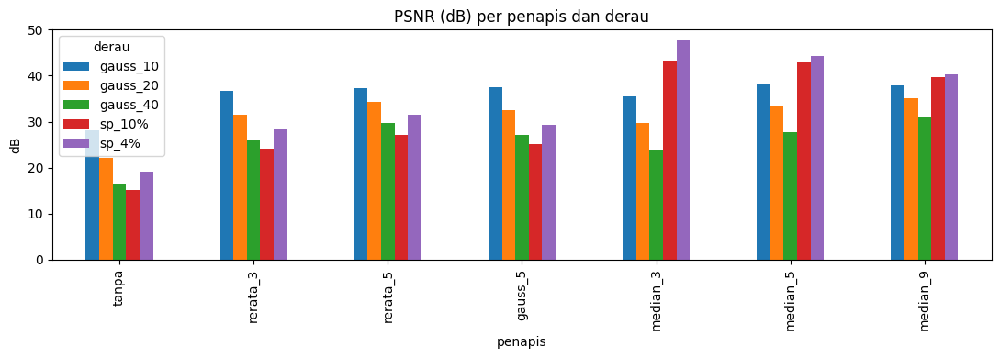

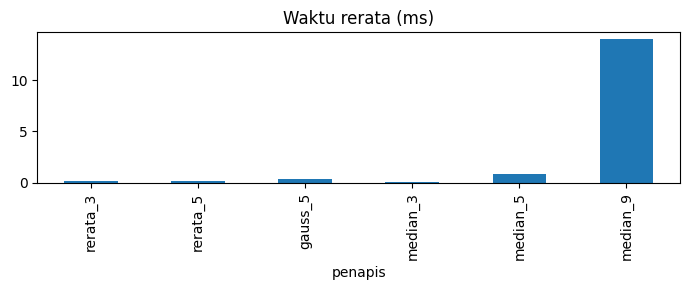

In [ ]:
rng = np.random.default_rng(42)
def derau_gauss(img, sd): return np.clip(img + rng.normal(0, sd, img.shape), 0, 255).astype(np.uint8)
def derau_sp(img, p):
    out = img.copy(); m = rng.random(img.shape); out[m < p / 2] = 0; out[m > 1 - p / 2] = 255; return out
def ukur_waktu(f, x, ulang=20):
    t = []
    for _ in range(ulang):
        t0 = time.perf_counter(); f(x); t.append(time.perf_counter() - t0)
    return 1000 * np.mean(t)
derau = {"gauss_10": derau_gauss(bersih, 10), "gauss_20": derau_gauss(bersih, 20), "gauss_40": derau_gauss(bersih, 40),
         "sp_4%": derau_sp(bersih, 0.04), "sp_10%": derau_sp(bersih, 0.10)}
penapis = {"rerata_3": lambda x: cv2.blur(x, (3, 3)), "rerata_5": lambda x: cv2.blur(x, (5, 5)),
           "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0), "median_3": lambda x: cv2.medianBlur(x, 3),
           "median_5": lambda x: cv2.medianBlur(x, 5), "median_9": lambda x: cv2.medianBlur(x, 9)}
baris = []
for dn, d in derau.items():
    baris.append([dn, "tanpa", cv2.PSNR(bersih, d), 0.0, kontras_bercak(d, md_, mb)])
    for pn, f in penapis.items():
        out = f(d); baris.append([dn, pn, cv2.PSNR(bersih, out), ukur_waktu(f, d), kontras_bercak(out, md_, mb)])
tabel = pd.DataFrame(baris, columns=["derau", "penapis", "PSNR_dB", "waktu_ms", "KB"]).round(2)
tabel.to_csv("hasil/b4_tabel_penapis.csv", index=False)
t11 = tabel[tabel.derau.isin(["gauss_20", "sp_4%"])].pivot(index="penapis", columns="derau", values=["PSNR_dB", "waktu_ms", "KB"])
order = ["tanpa", "rerata_3", "rerata_5", "gauss_5", "median_3", "median_5", "median_9"]
print("Tabel 11 (gauss_20 dan sp_4%)"); print(t11.loc[order])
pv = tabel.pivot(index="penapis", columns="derau", values="PSNR_dB").loc[order]
pv.plot(kind="bar", figsize=(11, 4), title="PSNR (dB) per penapis dan derau"); plt.ylabel("dB"); plt.tight_layout(); plt.savefig("hasil/b4_grafik_psnr.png"); plt.show()
tw = tabel[tabel.penapis != "tanpa"].pivot(index="penapis", columns="derau", values="waktu_ms").mean(axis=1).loc[order[1:]]
tw.plot(kind="bar", figsize=(7, 3), title="Waktu rerata (ms)"); plt.tight_layout(); plt.savefig("hasil/b4_grafik_waktu.png"); plt.show()

### Langkah 4.4 Apakah bercak kecil terjaga? (Kode 4.3)

           dI    KB
kernel             
1       27.81  4.32
3       28.17  4.44
5       26.98  4.30
9       20.37  3.72
15       6.17  1.64


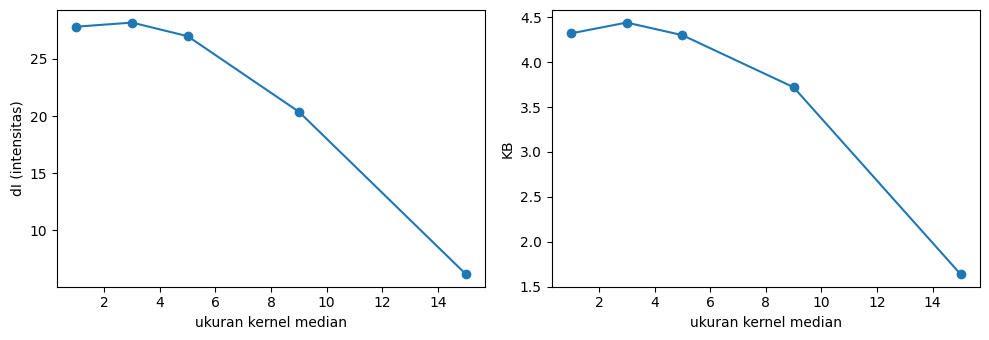

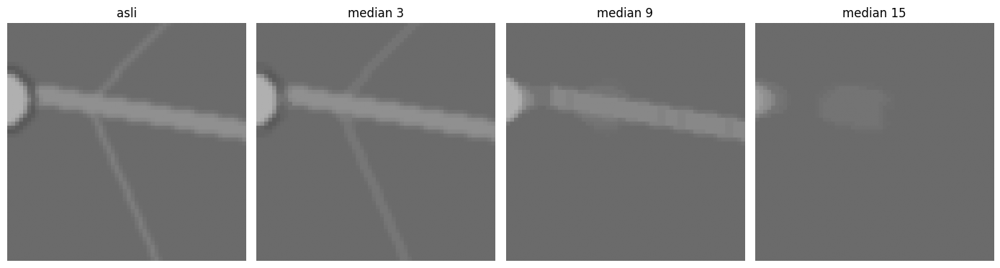

In [ ]:
def selisih_rerata(kanal, mask_daun, mask_bercak):
    k = kanal.astype(float); sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())
baris = []
for nm in label[label.kelas == "ringan"].nama_file:
    g_ = cv2.cvtColor(baca(f"data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    md2 = cv2.imread(f"data/sintetis/mask_daun/{nm}", 0); mb2 = cv2.imread(f"data/sintetis/mask_bercak/{nm}", 0)
    for k in [1, 3, 5, 9, 15]:
        out = g_ if k == 1 else cv2.medianBlur(g_, k)
        baris.append([nm, k, selisih_rerata(out, md2, mb2), kontras_bercak(out, md2, mb2)])
hasil_median = pd.DataFrame(baris, columns=["nama", "kernel", "dI", "KB"])
rata = hasil_median.groupby("kernel")[["dI", "KB"]].mean().round(2); print(rata)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(rata.index, rata.dI, "o-"); ax[0].set_xlabel("ukuran kernel median"); ax[0].set_ylabel("dI (intensitas)")
ax[1].plot(rata.index, rata.KB, "o-"); ax[1].set_xlabel("ukuran kernel median"); ax[1].set_ylabel("KB")
plt.tight_layout(); plt.savefig("hasil/b4_grafik_dI.png"); plt.show()
# potongan bercak diperbesar (crop) pada citra ringan teh_021
nm = "teh_021.png"; g_ = cv2.cvtColor(baca(f"data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY); mb2 = cv2.imread(f"data/sintetis/mask_bercak/{nm}", 0)
ys, xs = np.where(mb2 > 0); cy, cx = int(ys.mean()), int(xs.mean())
y0, x0 = max(cy - 30, 0), max(cx - 30, 0)
crops = [g_[y0:y0+60, x0:x0+60]] + [cv2.medianBlur(g_, k)[y0:y0+60, x0:x0+60] for k in (3, 9, 15)]
tampil([cv2.resize(c, None, fx=5, fy=5, interpolation=cv2.INTER_NEAREST) for c in crops], ["asli", "median 3", "median 9", "median 15"], ukuran=(14, 4))
plt.savefig("hasil/b4_crop_bercak.png"); plt.show()

### Langkah 4.5 Urutan meredam derau dan menajamkan (Kode 4.4)

In [ ]:
def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0); return cv2.addWeighted(x, 1 + k, blur, -k, 0)
noisy = derau["gauss_20"]; latar = md_ == 0
for nm, redam in {"Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0), "Median": lambda x: cv2.medianBlur(x, 5)}.items():
    A = redam(unsharp(noisy)); B = unsharp(redam(noisy))
    print(f"{nm}: tajam->redam PSNR={cv2.PSNR(bersih, A):.2f} sigma_latar={A[latar].std():.1f} | redam->tajam PSNR={cv2.PSNR(bersih, B):.2f} sigma_latar={B[latar].std():.1f}")

Gaussian: tajam->redam PSNR=30.38 sigma_latar=7.9 | redam->tajam PSNR=30.19 sigma_latar=8.3
Median: tajam->redam PSNR=30.11 sigma_latar=8.1 | redam->tajam PSNR=31.07 sigma_latar=7.3


### Langkah 4.6 PSNR 12 citra kondisi normal sebelum dan sesudah penapisan

In [ ]:
res = []
for i in range(1, 61, 5):
    nm = f"teh_{i:03d}.png"
    c = cv2.cvtColor(baca(f"data/sintetis/citra/{nm}"), cv2.COLOR_BGR2GRAY); bs = cv2.cvtColor(baca(f"data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    res.append([nm, cv2.PSNR(bs, c), cv2.PSNR(bs, cv2.medianBlur(c, 3)), cv2.PSNR(bs, cv2.GaussianBlur(c, (5, 5), 1.0))])
r4 = pd.DataFrame(res, columns=["citra", "PSNR_tanpa", "PSNR_median3", "PSNR_gauss5"]).round(2)
print(r4.to_string(index=False)); print("\nRerata:"); print(r4.iloc[:, 1:].mean().round(2))
r4.to_csv("hasil/b4_psnr_12_normal.csv", index=False)
print("\nP4.6: operasi kali kernel 5x5 -> 4000x3000:", 4000*3000*25/1e6, "juta | 640x480:", 640*480*25/1e6, "juta | rasio:", round(4000*3000/(640*480), 1))

      citra  PSNR_tanpa  PSNR_median3  PSNR_gauss5
teh_001.png       32.58         39.65        41.22
teh_006.png       29.98         37.34        39.41
teh_011.png       33.25         40.25        41.62
teh_016.png       29.69         37.04        39.08
teh_021.png       34.95         41.67        42.63
teh_026.png       31.70         38.82        40.34
teh_031.png       31.17         38.34        40.12
teh_036.png       34.87         41.49        41.94
teh_041.png       33.83         40.53        41.00
teh_046.png       31.64         38.77        40.54
teh_051.png       29.14         36.48        38.38
teh_056.png       35.73         42.19        41.78

Rerata:
PSNR_tanpa      32.38
PSNR_median3    39.38
PSNR_gauss5     40.67
dtype: float64

P4.6: operasi kali kernel 5x5 -> 4000x3000: 300.0 juta | 640x480: 7.68 juta | rasio: 39.1


### Jawaban Pertanyaan Analisis Bagian 4

**P4.1 Median vs rerata/Gaussian.** Pada setiap jendela 3 x 3, piksel garam (255) dan merica (0) hanya menempati ujung urutan data, sedangkan nilai ke-5 dari 9 data terurut tetap 60 (nilai daun). Karena itu median menghasilkan 60 di keempat posisi: nilai ekstrem **dibuang**. Rerata (74,22 sampai 75,44) dan Gaussian (57,44 sampai 104,44) ikut menghitung nilai ekstrem sehingga hasilnya berubah-ubah dan tercemar; pada Gaussian posisi (0,0), piksel 255 berada di pusat berbobot 4/16, hasilnya melonjak ke 104,44. Artinya, untuk derau garam dan merica median adalah penapis yang tepat karena ia kebal terhadap pencilan; rerata dan Gaussian hanya menyebarkan piksel rusak ke sekitarnya sehingga bintik terang yang kabur dapat menyerupai bercak.

**P4.2 Korelasi vs konvolusi.** Fungsi `konvolusi` pada slide **tidak membalik kernel**, jadi sebenarnya menghitung *korelasi silang*; `cv2.filter2D` juga mengerjakan korelasi (dokumentasi OpenCV menyebut ini). Itulah sebabnya hasil keduanya sama (selisih maksimum 0 untuk kedua kernel). Konvolusi sejati membalik kernel 180 derajat lebih dahulu; untuk kernel tak simetris (Sobel arah-x) hasilnya berbeda (selisih maksimum 255, karena membalik kernel Sobel mengubah tandanya sehingga respons positif menjadi negatif dan terpotong menjadi 0). Pada kernel rerata dan Gaussian, kernel simetris terhadap putaran 180 derajat, sehingga kernel yang dibalik identik dengan aslinya dan korelasi sama dengan konvolusi.

**P4.3 Penapis terbaik (Kode 4.2).**
- *Derau Gaussian 20:* PSNR tertinggi `median_9` (35,05 dB), lalu `rerata_5` (34,35), `median_5` (33,33), `gauss_5` (32,54), `rerata_3` (31,41), `median_3` (29,72); tanpa penapis 22,11 dB.
- *Garam-merica 4%:* PSNR tertinggi `median_3` (47,64 dB), jauh di atas rerata/Gaussian (28 sampai 31 dB).
- *Trade-off:* `median_9` unggul 0,7 dB atas `rerata_5` pada derau Gaussian, tetapi waktunya sekitar 100 kali lebih lama (sekitar 10 ms vs 0,09 ms) dan merusak bercak kecil (lihat P4.4). Untuk Gaussian, `rerata_5` atau `gauss_5` adalah pilihan seimbang (cepat, PSNR tinggi, KB 4,74 dan 4,26). Untuk garam-merica, `median_3` terbaik: PSNR tertinggi dan cepat (0,08 ms), KB 5,70 (median lebih besar memberi KB lebih tinggi, tetapi merusak bercak kecil). Keputusan berubah bila KB dan waktu ikut dipertimbangkan. *(Angka waktu berasal dari mesinku; cocokkan dengan milikmu.)*

**P4.4 Kernel median dan bercak ringan.** Rerata dI pada 20 citra ringan: kernel 1 = 27,81; 3 = 28,17; 5 = 26,98; 9 = 20,37; 15 = 6,17. Bercak mulai hilang pada kernel **9** (dI turun sekitar 27% dari tanpa penapis) dan nyaris lenyap pada kernel **15** (turun 78%). Alasan: median menghapus struktur yang lebih kecil dari sekitar setengah luas jendela, dan bercak ringan hanya berdiameter 10 sampai 18 piksel. KB tetap tinggi pada kernel sedang (3,72 pada kernel 9 vs 4,32 tanpa penapis) karena KB dibagi simpangan baku daun sehat: median juga meratakan tekstur dan derau daun sehat sehingga penyebut mengecil dan menutupi turunnya selisih. **Pelajaran:** satu ukuran dapat menyesatkan; laporkan dI dan KB bersamaan (pembilang dan penyebut) dan periksa visual, agar penapis yang membuang bercak tidak lolos hanya karena KB-nya baik.

**P4.5 Urutan redam dan tajam.** Tidak selalu lebih baik. Untuk Gaussian, tajam dahulu lalu redam memberi PSNR 30,38 dan σ latar 7,9; redam dahulu lalu tajam memberi 30,19 dan 8,3, hampir sama (bahkan urutan pertama sedikit lebih tinggi). Untuk median: tajam lalu redam 30,11 dan σ latar 8,1; redam lalu tajam 31,07 dan 7,3, jadi urutan redam dahulu lebih baik. Alasan: Gaussian dan unsharp masking keduanya linear dan tak berubah terhadap geseran (konvolusi), sehingga bersifat komutatif; urutan tidak mengubah hasil (selisih kecil hanya akibat pembulatan dan *clipping* 8 bit). Median tidak linear, jadi urutan penting: bila menajamkan dahulu, derau ikut diperkuat sebelum median dan tidak seluruhnya terbuang.

**P4.6 Jumlah operasi.** Kernel 5 x 5 butuh 25 perkalian per piksel: foto 4000 x 3000 = 12 juta piksel x 25 = **300 juta** perkalian; citra 640 x 480 = 307.200 piksel x 25 = **7,68 juta** (39 kali lebih sedikit). Pada Kode 4.1, kernel 3 x 3 (9 perkalian) di citra 640 x 480 memakan sekitar 1,3 detik dengan perulangan Python; kernel 5 x 5 kira-kira 3,6 detik, dan untuk foto asli sekitar 39 kali lebih lama (dua menit lebih). Itu tidak sesuai kebutuhan pengguna nomor 4 (cepat di ponsel kelas menengah). Jadi foto harus diperkecil ke 640 piksel dan memakai fungsi pustaka (`filter2D`, `blur`, `medianBlur`) yang dioptimalkan, yang selesai dalam sekitar 0,4 sampai 4 ms.

**P4.7 Wajah tidak sengaja terfoto.** Blur ringan tidak cukup karena struktur wajah, bentuk kepala, rambut, pakaian, dan konteks masih dapat dikenali, dan blur ringan dapat dipulihkan sebagian (dekonvolusi) atau dikenali oleh model pengenalan wajah. Prosedur lebih aman: (1) hentikan penyimpanan dan jangan unggah foto itu; (2) deteksi wajah lalu tutup dengan kotak solid (bukan blur) atau potong bagian itu; (3) hapus berkas asli dan EXIF, simpan hanya versi yang sudah aman; (4) bila memungkinkan ambil ulang foto tanpa orang; (5) minta persetujuan petani dan batasi akses.

## Bagian 5. Integrasi: Rangkaian Praproses SIMUTEH

### Langkah 5.1 Modul `src/praproses.py`
Modul sudah ditulis oleh sel `%%writefile` di Bagian 1 dengan lima langkah: (1) ubah ukuran `INTER_AREA` dengan rasio aspek tetap, (2) koreksi gamma lewat LUT, (3) CLAHE hanya di kanal V (HSV), (4) penapis derau (rerata/Gaussian/median), (5) *unsharp masking* opsional. Urutan mengikuti Gambar 5.

### Langkah 5.2 Evaluasi kuantitatif (Kode 5.2)
Kanal terpilih: **R** (indeks BGR 2), berdasarkan Bagian 2 (P2.2). Saya membandingkan beberapa kandidat parameter pada 40 citra berbercak, lalu memilih parameter final.

In [ ]:
from praproses import praproses, simpan_param
KANAL = 2   # R, kanal terbaik Bagian 2
label = pd.read_csv("data/sintetis/label.csv")
def evaluasi(param, kelas_tolak="sehat"):
    r = []
    for _, d in label[label.kelas != kelas_tolak].iterrows():
        im = baca(f"data/sintetis/citra/{d.nama_file}")
        a = cv2.imread(f"data/sintetis/mask_daun/{d.nama_file}", 0); b_ = cv2.imread(f"data/sintetis/mask_bercak/{d.nama_file}", 0)
        o = praproses(im, param)
        r.append([d.kondisi_cahaya, kontras_bercak(im[:, :, KANAL], a, b_), kontras_bercak(o[:, :, KANAL], a, b_)])
    t = pd.DataFrame(r, columns=["kondisi", "KB_sebelum", "KB_sesudah"]).groupby("kondisi").mean().loc[URUT]
    t["Perubahan_%"] = (t.KB_sesudah / t.KB_sebelum - 1) * 100
    return t.round(2)
kandidat = {
 "contoh (clahe 2, median 3)":  {"gamma": 1.0, "clahe_clip": 2.0, "penapis": "median", "kernel": 3},
 "tanpa CLAHE, median 3":        {"gamma": 1.0, "clahe_clip": 0,   "penapis": "median", "kernel": 3},
 "clahe 2 tile 4, median 3":     {"gamma": 1.0, "clahe_clip": 2.0, "clahe_tile": 4, "penapis": "median", "kernel": 3},
 "clahe 2, gaussian 5":          {"gamma": 1.0, "clahe_clip": 2.0, "penapis": "gaussian", "kernel": 5, "sigma": 1.0},
 "clahe 1, median 3 (FINAL)":    {"gamma": 1.0, "clahe_clip": 1.0, "penapis": "median", "kernel": 3},
}
ringkas = {}
for nm, p in kandidat.items():
    t = evaluasi(p); ringkas[nm] = t[["KB_sebelum", "KB_sesudah"]].mean().round(2).to_dict()
    print("\n##", nm); print(t)
print("\nRingkasan rerata KB (semua kondisi):"); print(pd.DataFrame(ringkas).T)


## contoh (clahe 2, median 3)
                KB_sebelum  KB_sesudah  Perubahan_%
kondisi                                            
normal                9.92       11.34        14.41
gelap                 8.99       16.79        86.87
terang                6.39        6.14        -4.00
kontras_rendah        3.50        4.39        25.41
bayangan              4.53        7.76        71.24

## tanpa CLAHE, median 3
                KB_sebelum  KB_sesudah  Perubahan_%
kondisi                                            
normal                9.92       14.80        49.26
gelap                 8.99       15.79        75.70
terang                6.39       10.61        65.92
kontras_rendah        3.50        7.30       108.70
bayangan              4.53        5.77        27.36

## clahe 2 tile 4, median 3
                KB_sebelum  KB_sesudah  Perubahan_%
kondisi                                            
normal                9.92       11.61        17.12
gelap                 8.99    

In [ ]:
# Parameter final -> JSON, lalu Tabel 12
final = {"lebar": 640, "gamma": 1.0, "clahe_clip": 1.0, "clahe_tile": 8, "penapis": "median", "kernel": 3, "sigma": 1.0, "tajam_k": 0.0}
simpan_param(final, "hasil/param_praproses.json")
print(open("hasil/param_praproses.json").read())
tabel12 = evaluasi(final); print("Tabel 12 (kanal R, parameter final):"); print(tabel12)
tabel12.to_csv("hasil/b5_tabel12.csv")

{
  "lebar": 640,
  "gamma": 1.0,
  "clahe_clip": 1.0,
  "clahe_tile": 8,
  "penapis": "median",
  "kernel": 3,
  "sigma": 1.0,
  "tajam_k": 0.0
}
Tabel 12 (kanal R, parameter final):
                KB_sebelum  KB_sesudah  Perubahan_%
kondisi                                            
normal                9.92       13.31        34.27
gelap                 8.99       16.77        86.62
terang                6.39        8.49        32.74
kontras_rendah        3.50        6.21        77.37
bayangan              4.53        7.58        67.26


### Langkah 5.3 Uji bercak palsu pada kelas sehat
Simpangan baku kanal R pada area daun dihitung sebelum dan sesudah praproses. Area daun dikikis 15 piksel (erosi) agar tepi daun tidak ikut terhitung. Selain itu dihitung banyaknya piksel yang menyimpang lebih dari 4σ dari rerata daun (calon "titik terang").

                std_sebelum  std_sesudah  piksel_>4sigma
kondisi                                                 
normal                11.13         7.27          692.50
gelap                 10.13         5.64          148.50
terang                10.15         7.59          479.25
kontras_rendah         9.88         5.94           72.00
bayangan              12.40         8.44          241.75


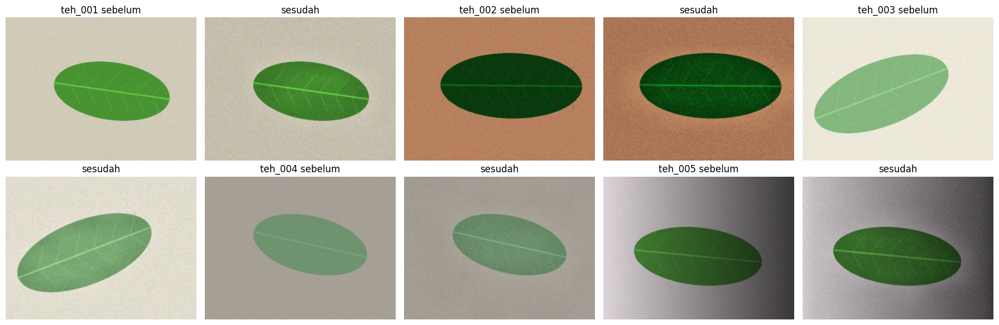

In [ ]:
r = []
for _, d in label[label.kelas == "sehat"].iterrows():
    im = baca(f"data/sintetis/citra/{d.nama_file}"); a = cv2.imread(f"data/sintetis/mask_daun/{d.nama_file}", 0)
    o = praproses(im, final); dalam = cv2.erode(a, np.ones((15, 15), np.uint8)) > 0
    s0, s1 = im[:, :, KANAL][dalam].std(), o[:, :, KANAL][dalam].std()
    z = (o[:, :, KANAL].astype(float) - o[:, :, KANAL][dalam].mean()) / (s1 + 1e-6)
    r.append([d.kondisi_cahaya, s0, s1, int((np.abs(z[dalam]) > 4).sum())])
uji = pd.DataFrame(r, columns=["kondisi", "std_sebelum", "std_sesudah", "piksel_>4sigma"]).groupby("kondisi").mean().loc[URUT].round(2)
print(uji); uji.to_csv("hasil/b5_uji_sehat.csv")
# panel sebelum dan sesudah untuk satu citra per kondisi (kelas sehat: teh_001 s.d. teh_005)
daftar, judul = [], []
for i in range(1, 6):
    im = baca(f"data/sintetis/citra/teh_{i:03d}.png"); daftar += [im, praproses(im, final)]; judul += [f"teh_{i:03d} sebelum", "sesudah"]
tampil(daftar, judul, baris=2, ukuran=(18, 6)); plt.savefig("hasil/b5_panel_sehat.png"); plt.show()

### Langkah 5.4 Justifikasi (Tabel 13)

| Langkah | Parameter final | Alasan dan bukti | Risiko bila salah atur |
|---|---|---|---|
| 1. Ubah ukuran | lebar 640, `INTER_AREA` | Mengurangi 39 kali operasi per penapis (P4.6) dan cukup cepat untuk ponsel; memenuhi kebutuhan 4. Syarat jarak ≤ 22,9 cm agar bercak tetap ≥ 10 piksel (2.1 d) | Terlalu kecil: bercak ringan hilang (Tabel sampling, P2.5); terlalu besar: lambat |
| 2. Koreksi gamma | 1,0 (tidak dipakai) | Gamma tetap tidak menolong semua kondisi (gamma 0,5 menurunkan KB bayangan, Tabel 10; gamma 0,6 pada teh_042 menurunkan KB gelap dari 3,41 ke 2,83); kondisi gelap/terang lebih baik ditangani aturan adaptif (P3.5) | Gamma ekstrem membuat daun sehat pucat atau gelap dan mengubah kesan warna |
| 3. CLAHE kanal V | clip 1,0; tile 8 | KB rata-rata 10,47 (vs 9,28 untuk clip 2); KB naik di kelima kondisi (Tabel 12); kanal V menjaga Hue (P3.4) | Clip besar atau tile kecil menguatkan derau dan tulang daun menjadi bintik mirip bercak (P3.6); pada kondisi terang clip 2 justru menurunkan KB |
| 4. Redam derau | median, kernel 3 | Median 3 terbaik untuk garam-merica dan cepat (Tabel 11); kernel kecil menjaga bercak ringan (P4.4: dI tetap 28 pada kernel 3) | Kernel ≥ 9 menghapus bercak ringan; rerata/Gaussian mengaburkan tepi bercak |
| 5. Tajamkan | tidak dipakai (k = 0) | Derau sudah ditekan; menajamkan dapat memperkuat sisa derau, dan urutan memengaruhi hasil untuk median (P4.5) | Penajaman berlebihan menimbulkan halo dan titik terang palsu |

Diagram rangkaian dengan parameter final dibuat pada sel berikut.

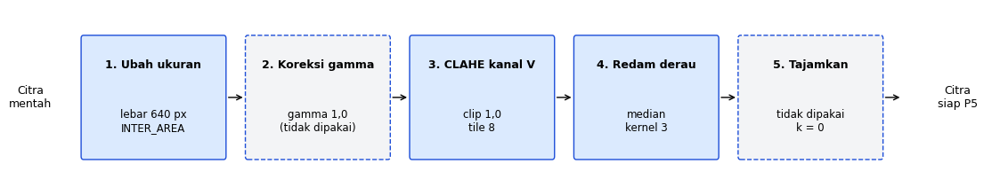

In [ ]:
langkah = [("1. Ubah ukuran", "lebar 640 px\nINTER_AREA"), ("2. Koreksi gamma", "gamma 1,0\n(tidak dipakai)"),
           ("3. CLAHE kanal V", "clip 1,0\ntile 8"), ("4. Redam derau", "median\nkernel 3"), ("5. Tajamkan", "tidak dipakai\nk = 0")]
fig, ax = plt.subplots(figsize=(14, 2.6)); ax.axis("off"); ax.set_xlim(0, 20); ax.set_ylim(0, 3)
ax.text(0.1, 1.5, "Citra\nmentah", ha="center", va="center", fontsize=9)
for i, (a_, b_) in enumerate(langkah):
    x = 1.2 + i * 3.4
    ax.add_patch(FancyBboxPatch((x, 0.5), 2.9, 2, boxstyle="round,pad=0.05", fc="#dbeafe" if i not in (1, 4) else "#f3f4f6", ec="#1d4ed8", ls="-" if i not in (1, 4) else "--"))
    ax.text(x + 1.45, 2.0, a_, ha="center", fontsize=9, fontweight="bold"); ax.text(x + 1.45, 1.1, b_, ha="center", va="center", fontsize=8.5)
    ax.annotate("", xy=(x + 3.35, 1.5), xytext=(x + 2.95, 1.5), arrowprops=dict(arrowstyle="->"))
ax.text(19.3, 1.5, "Citra\nsiap P5", ha="center", va="center", fontsize=9)
plt.savefig("hasil/b5_diagram_final.png", dpi=150, bbox_inches="tight"); plt.show()

### Langkah 5.5 Reprodusibilitas
### Jawaban Pertanyaan Analisis Bagian 5

**P5.1 KB naik di semua kondisi?** Ya, dengan parameter final (CLAHE clip 1, median 3, kanal R): normal 9,92 menjadi 13,31 (+34,3%), gelap 8,99 menjadi 16,77 (+86,6%), terang 6,39 menjadi 8,49 (+32,7%), kontras rendah 3,50 menjadi 6,21 (+77,4%), bayangan 4,53 menjadi 7,58 (+67,3%). Rata-rata 6,67 menjadi 10,47. Kondisi tersulit adalah **kontras rendah** (KB sesudah terendah, 6,21) lalu **bayangan** (7,58). Pada kontras rendah, rentang intensitas daun dan bercak dimampatkan (f = 0,35 f + 95) sehingga selisih bercak-daun kecil dibanding derau; pada bayangan, gradasi cahaya membuat rerata daun berbeda antar-sisi sehingga simpangan baku daun besar. Catatan: sebagian kenaikan berasal dari median yang menurunkan derau (penyebut KB mengecil), bukan hanya dari CLAHE (tanpa CLAHE KB rata-rata sudah 10,85).

**P5.2 KB turun?** Pada parameter contoh (CLAHE clip 2, median 3) KB kondisi **terang** turun dari 6,39 menjadi 6,14 (-4%). Sebab: citra terang punya 75% piksel di atas 205, mendekati jenuh; CLAHE clip 2 menaikkan kontras lokal derau dan variasi daun sehat (penyebut membesar), sehingga rasio KB turun. Perbaikan: pilih parameter otomatis dari statistik histogram. Aturan pada P3.5 (CLAHE hanya bila bayangan atau gelap, tanpa CLAHE bila terang atau normal) menghasilkan KB terang 10,61 dan rerata keseluruhan 11,38. Pada parameter final (clip 1) tidak ada kondisi yang turun.

**P5.3 Bercak palsu?** Pada 20 citra sehat, simpangan baku kanal R di area daun justru **turun** di semua kondisi (normal 11,13 menjadi 7,27; gelap 10,13 menjadi 5,64; terang 10,15 menjadi 7,59; kontras rendah 9,88 menjadi 5,94; bayangan 12,40 menjadi 8,44), jadi keragaman daun sehat tidak membengkak. Jumlah piksel yang menyimpang lebih dari 4σ paling besar pada kondisi **normal** (sekitar 690 piksel) dan **terang** (sekitar 480); ini adalah tulang daun yang memang lebih terang (digambar 1,35 kali lebih terang). Pada panel `b5_panel_sehat.png` yang saya periksa, tidak muncul bintik terang baru pada daun sehat; yang tampak hanya tulang dan cabang daun menjadi lebih tegas. *(Periksa panel milikmu sendiri untuk memastikan.)* Risiko: tulang daun terang pada kondisi normal/terang dapat dikira bercak pada tahap segmentasi dan menyebabkan daun sehat salah diklasifikasikan sebagai bercak ringan pada P11; ini perlu diwaspadai dengan fitur bentuk (garis memanjang vs bulat).

**P5.4 Praproses yang sama untuk data latih dan uji.** Model mempelajari distribusi fitur dari citra yang sudah dipraproses. Jika data uji dipraproses berbeda (mis. tanpa CLAHE atau dengan ukuran lain), fitur uji bergeser dari fitur latih (*train-serving skew*), sehingga akurasi pada uji tampak lebih rendah atau tidak mewakili kondisi nyata, dan perbandingan antar-model tidak adil. Parameter juga tidak boleh dipilih dengan melihat data uji (kebocoran data); itu sebabnya parameter disimpan di JSON dan dipakai ulang tanpa diubah.

**P5.5 Nilai AIK.**
- **Jujur:** semua angka dilaporkan apa adanya dari keluaran kode dengan SEED sendiri, termasuk penurunan KB pada kondisi terang (parameter contoh) dan keterbatasan KB (P2.4, P4.4); dataset sintetis dinyatakan tidak mewakili foto nyata; bagian yang dibantu AI dicantumkan di refleksi.
- **Amanah:** EXIF dihapus, tidak ada wajah atau lokasi di repository; repository privat, SEED, versi pustaka, parameter JSON, dan tag git dicatat agar hasil dapat ditelusuri dan diulang; keputusan akhir mutu tetap di tangan petugas.
